# QC-RDH: Quantum-Chaotic Reversible Data Hiding for Telemedicine
### Reproducible notebook: design, gate-level circuits, verification and all results

This notebook is a quantum redesign of *"Chaos-Induced Reversible Data Hiding Scheme leveraging Paillier Cryptosystem and Huffman Encoding"* that changes the original as little as possible. Every quantum step is a **valid unitary on an NEQR image state**, and it is **verified gate-by-gate** against the classical reference implementation.

| Stage | Original paper | QC-RDH (this work) | Why the change is *necessary* |
|---|---|---|---|
| Key distribution | "shared over a secure channel" | **BB84 QKD**, giving a 256-bit key (Sec. 2) | removes the unproven secure-channel assumption; information-theoretic eavesdropper detection |
| Key schedule | 2-D rational chaotic map | **same map** (Eq. 1), hashed and combined with the QKD key | retained; Grover's search halves symmetric strength, so the 256-bit QKD key keeps ≥128-bit post-quantum security |
| Image model | classical 8-bit | **extended NEQR**: 2n position qubits plus 10 intensity qubits | standard quantum image representation |
| Enlargement | (2M−1)×(2N−1), inserted pixels = 1 | **quantum nearest-neighbour scaling to 2M×2N**: one H gate per axis | NEQR requires a 2ⁿ×2ⁿ grid; setting inserted pixels to 1 is not unitary |
| Embedding | parity bit + 2P+D with ×2/×3 flags, overflow quotients | **\|c⟩→\|4c+D⟩**: qubit rotation plus a position-controlled write of D | unitary, no overflow (max 1023 < 2¹⁰), no flags, no shared seed blocks |
| Text coding | Huffman (table never sent) | **canonical Huffman over UTF-8 bytes plus a header** (table and 32-bit length) | receiver can decode |
| Encryption | Paillier (19-bit modulus) | **position scrambling by Draper QFT adders, then a key oracle (XOR)** | Paillier is broken by Shor's algorithm; ciphertext did not fit a pixel |
| Differential security | not addressed | **synthetic nonce = HMAC(K, cover‖text)**, sent publicly | **Theorem 1**: no fixed-key unitary can diffuse; plaintext-dependent selection of the unitary is *necessary* |
| Integrity | none | receiver recomputes the nonce, checks the 4 redundant copies and the padding | detects tampering and a wrong key |
| Extraction | inverse arithmetic | **inverse circuit E†, then computational-basis measurement** (shots counted) | measurement and no-cloning are made explicit |

**Deployment modes.** (A) Fully quantum channel: the stego state is sent as a quantum state, so the receiver needs about N·ln N copies to read every pixel (Sec. 9). (B) Hybrid: QKD plus quantum processing at each end, with the classical ciphertext transmitted. Every operation is a basis-state permutation, so it commutes with computational-basis measurement. Both modes therefore give bit-identical results, and this is also why the classical twin is an *exact* simulator.

## Contributions and novelty (verified against the full texts of the closest prior work)
The five closest papers were read in full: Pawela, arXiv:2508.16382v4 (2026); Saini et al., NEQRX, *IEEE TDSC* 23(5), 2026; Mogos & Lam, *Cybersecurity* 9:118, 2026; Zeng et al., *Optica Applicata* 55(4), 2025; Grassl, *QIP* 20:183, 2021. A web search of the 2019–2026 literature was also run.

### Novelty claims that survived the check
| # | Claim | Closest prior work and the gap |
|---|---|---|
| **N1** | **Theorem 1 (exact invariance).** For every fixed-key unitary mapping NEQR-family images to NEQR-family images (any gates, ancillas allowed), d_H(E(I),E(J))/N′ = d_H(I,J)/N, i.e. the *number of changed pixels* is fixed by unitarity. | Pawela 2026, Sec. III-E, makes only the qualitative state-level remark (overlap of one-pixel-different states is preserved; NPCR is "a property of the measurement-and-mask step"). It gives no Hamming-distance statement, no bound and no proof for general ciphers. **We cite it as the precursor.** |
| **N2** | **Corollary 1 (NPCR ceiling = 100/N %)** for plaintext changes in any such cipher; hence reported plaintext NPCR ≈ 99.6 % for fixed-key quantum pipelines cannot come from the unitary. | Not stated in any of the five papers. NEQRX (Sec. V-C4) measures NPCR only between *different keys*, which is consistent with N2. Two 2026 reviews note empirically that NPCR ≈ 99.6 % is reported almost everywhere and no longer separates schemes (V. & H. Prajapati, preprint, Oct 2026; *Front. Phys.* 2026, doi:10.3389/fphy.2026.1878327); N2 gives the reason. |
| **N3** | **Corollary 2 (structure).** A size-preserving fixed-key quantum image cipher is a Hamming-graph automorphism: a pixel permutation plus position-wise substitution. | Not found. Classical permutation/substitution cryptanalysis exists (Li & Lo 2011; QCMDC-IEA cryptanalysis, *Expert Syst. Appl.*). The *reduction of every* fixed-key quantum image cipher to that class is new. |
| **N4** | **Concrete break of the NEQRX-style class** (GAT scrambling + logistic-map XOR + LSB embedding) with **4 chosen covers**, recovering a hidden 512×512 patient image (Sec. 6d), and of the fixed-key variant of our own scheme (Sec. 6c). | NEQRX reports no chosen-plaintext analysis; Grassl 2021 shows a *different* flaw (key-image entanglement breaks decryption). The attack technique is classical; its application to quantum RDH is new. |
| **N5** | **Proposition 3 (necessity) + construction.** Plaintext sensitivity requires the unitary to be selected by plaintext-dependent classical side information. QC-RDH realises this with a content-bound synthetic nonce (SIV = HMAC(K, cover‖text)). | Pawela 2026 states that avoiding the leakage "would require" per-message randomisation and a security model, "which we do not attempt". Plaintext-hashed keys exist in classical-control quantum ciphers (SHA-512/384), but without the necessity result or authentication. |
| **N6** | **Content-authenticated quantum RDH**: the receiver detects any modification of the stego image and any wrong key (nonce recomputation, 4-copy consistency, keyed padding), with exact image and text recovery. | Mogos & Lam 2026 apply HMAC to *key-exchange packets* (4×4 cover, not reversible); Zeng 2025 "authenticates" by a visible identity watermark; NEQRX has no integrity check. None authenticates the recovered content in quantum RDH. Related but different: Abd El-Latif et al. (IEEE Access 6, 2018) authenticate an embedded message with a hash in an entanglement-based quantum steganography protocol (not image RDH, no exact cover recovery); Santhiya Devi et al. (2019) use cellular-automata authentication inside NEQR encryption (not RDH, no content MAC). |
| **N7** | **Every quantum step is a valid unitary, verified gate-by-gate** against an exact classical twin, replacing the original paper's invalid steps ((2M−1)×(2N−1) enlargement, non-unitary pixel insertion, overflow flags, untransmitted Huffman table, Shor-breakable Paillier). | Specific to this paper; it is a correctness contribution, not a novelty claim on its own. |

### Not claimed (prior art, reused)
| Building block | Published in |
|---|---|
| NEQR nearest-neighbour scaling / interpolation for steganography | Jiang & Wang, *QIP* 2015; Zhao et al., *IJTP* 2021; Li, Yan et al., *SPIC* 2023 |
| Quantum encryption + RDH with affine scrambling and chaos, in Qiskit | Saini et al., NEQRX, *IEEE TDSC* 2026 |
| BB84 / QKD combined with image encryption or steganography, HMAC/HKDF key handling | Mogos & Lam 2026; Bright Anna Bell & Vigila 2026; Mallick et al. 2025 |
| Plaintext-hashed keys in quantum image ciphers | 2-D quantum-walk NEQR cipher (SHA-512), *Signal Processing*; QTRNG/DNA scheme (SHA-384), *Sci. Rep.* 2025 |
| Unitary overlap preservation of NEQR states (qualitative) | Pawela, arXiv:2508.16382 (2026) |
| Classical chosen-plaintext attacks on permutation/substitution image ciphers | Li & Lo, *Signal Process.* 91(4), 2011; cryptanalysis of QCMDC-IEA, *Expert Syst. Appl.* |
| Equivalent-key reduction C = P∘π ⊕ K and all-zero + base-256 position attack (classical ciphers) | e.g. *Fractal Fract.* 10(11):770, 2026; row-column permutation KPA, *FAIA* 2026 |
| Empirical observation that NPCR/UACI no longer discriminate quantum image ciphers | Prajapati & Prajapati, review preprint (Oct 2026); *Front. Phys.* 2026 review |

**Honest framing for the paper.** The contribution is a *security-theoretic* one (N1–N5) together with an *authenticated, verified* construction (N6–N7), not a capacity or speed record. A reviewer may describe N1 as a short consequence of unitarity; the answer is that its exact form (N2–N3) and the attack (N4) are absent from the literature, and that published quantum RDH schemes report metrics that N2 shows to be key-sensitivity only.

*Search log (7 Nov 2026): the queries below plus 14 variants were run through web search; Scopus/WoS/IEEE Xplore could not be queried directly from this environment. Google Scholar was then queried through a browser extension (6 queries, incl. NEQR + RDH + HMAC/tamper detection and Hamming/changed-pixel + unitary); no source stating N1–N3 or N6 was found.*

*Before submission run a final Scopus / Google Scholar check (queries: "unitary" AND "NPCR" AND "quantum image"; "quantum image encryption" AND "Hamming distance"; "quantum reversible data hiding" AND "authentication").*

### Anticipated reviewer questions (answered in this notebook)
1. **"Is the quantum part just relabelled classical code?"** The circuits are built from real gates (H, SWAP, MCX, QFT, controlled-phase) and simulated on a statevector. Sec. 5 shows the 18-qubit circuit output equals the classical twin **bit-for-bit**. The quantum contributions are QKD key distribution, NEQR storage of 2²ⁿ pixels in 2n+10 qubits, and the absence of any Shor-breakable primitive. **We do not claim a computational speed-up.**
2. **"Is the position permutation efficiently implementable?"** Yes. Each round is two affine shears built from Draper adders, O(n²) gates each (Sec. 4, diagram c). An arbitrary lookup permutation would not be efficient, so we do not use one.
3. **"Why no pixel-diffusion stage?"** Theorem 1 (Sec. 6) proves that no fixed-key unitary can diffuse, and it is verified at gate level. Sensitivity comes from the synthetic nonce (Table C).
4. **"Why keep the chaotic map if SHA-256/HMAC is used?"** The map is the original paper's key schedule and contributes key material and parameter sensitivity. Security is **not** claimed from chaos alone; it rests on HMAC/SHAKE with the 256-bit QKD key.
5. **"How is the image read from a quantum state?"** By measurement. Each shot returns one (position, intensity) pair exactly, and the shot count is reported. The 4 redundant copies per cover pixel also act as a read-out consistency check.
6. **"Capacity per which pixel?"** Both are reported. It is 2 bpp per stego pixel and 8 bpp per original pixel, and the stego image has 4× the pixels at 10 bits each.

In [ ]:
!pip -q install qiskit qiskit-aer pylatexenc scikit-image pandas matplotlib

In [ ]:
%%writefile core.py
# =====================================================================================
#  QC-RDH core — classical twin of the quantum circuits.
#  Every step below is the classical reversible function whose permutation-unitary is
#  implemented gate-by-gate in Section 6 of the notebook (and verified to agree exactly).
# =====================================================================================
import hashlib, hmac, struct, math, heapq
import numpy as np

NBITS_C = 10                                # intensity register: 8-bit cover + 2 embedded bits
DEFAULT_CHAOS = dict(a=-2.8, b=1.0, c=-0.1, d=-0.1, x0=7.0, y0=0.0, T=1000)
ROUNDS = 4                                  # cat-map shear rounds for position scrambling

# ---------------------------------------------------------------- 1. chaotic key schedule
def rational_map(x, y, a, b, c, d):
    return x + a * x / (1 + y * y) + b, y + c * x + d

def chaos_digest(chaos, n_states=256):
    """Iterate the 2-D rational map (paper Eq. 1), discard transient, hash the trajectory."""
    x, y = float(chaos["x0"]), float(chaos["y0"])
    a, b, c, d = (float(chaos[k]) for k in "abcd")
    for _ in range(int(chaos["T"])):
        x, y = rational_map(x, y, a, b, c, d)
    h = hashlib.sha256()
    for _ in range(n_states):
        x, y = rational_map(x, y, a, b, c, d)
        if not (math.isfinite(x) and math.isfinite(y) and abs(x) < 1e6 and abs(y) < 1e6):
            raise ValueError("invalid chaotic key: trajectory diverges for these parameters")
        h.update(struct.pack("<dd", x, y))
    return h.digest()

def master_key(qkd_key: bytes, chaos=DEFAULT_CHAOS):
    """K = HMAC(K_QKD, chaos digest): needs BOTH the 256-bit QKD key and the chaotic parameters."""
    return hmac.new(qkd_key, b"QC-RDH|" + chaos_digest(chaos), hashlib.sha256).digest()

def siv_nonce(K, cover, payload: bytes):
    """Synthetic IV: deterministic, depends on every cover pixel and payload byte (SIV construction)."""
    m = hmac.new(K, b"nonce|", hashlib.sha256)
    m.update(struct.pack("<II", *cover.shape)); m.update(cover.astype("<u2").tobytes()); m.update(payload)
    return m.digest()[:16]

def session(K, nonce):  return hmac.new(K, b"session|" + nonce, hashlib.sha256).digest()
def xof(seed, label, nbytes): return hashlib.shake_256(seed + label).digest(nbytes)

def round_constants(S, n):
    raw = np.frombuffer(xof(S, b"rounds", 8 * 4 * ROUNDS), dtype="<u8").reshape(ROUNDS, 4)
    return [tuple(int(v) & ((1 << n) - 1) for v in r) for r in raw]   # (alpha, beta, gamma, delta)

def keystream(S, side):                     # 10-bit key value for every position
    raw = np.frombuffer(xof(S, b"ks", 2 * side * side), dtype="<u2").astype(np.int64)
    return (raw & ((1 << NBITS_C) - 1)).reshape(side, side)

# ---------------------------------------------------------------- 2. position scrambling (quantum shears)
def scramble(Y, X, consts, n):
    m = (1 << n) - 1
    for al, be, ga, de in consts:
        X = (X + al * Y + be) & m            # Draper adder:  |x> -> |x + alpha*y + beta>
        Y = (Y + ga * X + de) & m            # Draper adder:  |y> -> |y + gamma*x + delta>
    return Y, X

def unscramble(Y, X, consts, n):
    m = (1 << n) - 1
    for al, be, ga, de in reversed(consts):
        Y = (Y - ga * X - de) & m
        X = (X - al * Y - be) & m
    return Y, X

# ---------------------------------------------------------------- 3. canonical Huffman over UTF-8 bytes + header
H_NSYM, H_SYM, H_LEN, H_PLEN = 9, 8, 5, 32

def _huff_lengths(data: bytes):
    freq = np.bincount(np.frombuffer(data, np.uint8), minlength=256)
    syms = [s for s in range(256) if freq[s]]
    if not syms: return {}
    if len(syms) == 1: return {syms[0]: 1}
    heap = [(int(freq[s]), s, [s]) for s in syms]; heapq.heapify(heap)
    depth = {s: 0 for s in syms}; tie = 256
    while len(heap) > 1:
        f1, _, a = heapq.heappop(heap); f2, _, b = heapq.heappop(heap)
        for s in a + b: depth[s] += 1
        heapq.heappush(heap, (f1 + f2, tie, a + b)); tie += 1
    assert max(depth.values()) < (1 << H_LEN), "code length exceeds header field"
    return depth

def _canonical(lengths):
    codes, code, prev = {}, 0, 0
    for s, l in sorted(lengths.items(), key=lambda kv: (kv[1], kv[0])):
        code <<= (l - prev); prev = l; codes[s] = format(code, "0%db" % l); code += 1
    return codes

def encode_payload(data: bytes) -> str:
    ln = _huff_lengths(data); codes = _canonical(ln)
    body = "".join(codes[b] for b in data)
    hdr = format(len(ln), "0%db" % H_NSYM)
    for s, l in sorted(ln.items(), key=lambda kv: (kv[1], kv[0])):
        hdr += format(s, "08b") + format(l, "0%db" % H_LEN)
    return hdr + format(len(body), "0%db" % H_PLEN) + body

def decode_payload(bits: str) -> bytes:
    p = 0; n = int(bits[p:p + H_NSYM], 2); p += H_NSYM; ln = {}
    for _ in range(n):
        s = int(bits[p:p + 8], 2); p += 8; ln[s] = int(bits[p:p + H_LEN], 2); p += H_LEN
    plen = int(bits[p:p + H_PLEN], 2); p += H_PLEN
    if p + plen > len(bits) or 0 in ln.values(): raise ValueError("corrupt header")
    inv = {c: s for s, c in _canonical(ln).items()}; out = bytearray(); cur = ""
    for b in bits[p:p + plen]:
        cur += b
        if cur in inv: out.append(inv[cur]); cur = ""
        elif len(cur) > 31: raise ValueError("corrupt code stream")
    return bytes(out)

# ---------------------------------------------------------------- 4. sender / receiver
def capacity(M, N):  return 8 * M * N        # 2 bits in every pixel of the 2M x 2N enlarged image

def embed(cover, text, qkd_key, chaos=DEFAULT_CHAOS):
    """Returns (stego ciphertext 2M x 2N with 10-bit values, public nonce)."""
    M, N = cover.shape
    assert M == N and M & (M - 1) == 0, "NEQR needs a 2^n x 2^n cover (pad/resize first)"
    side, n = 2 * M, int(math.log2(2 * M))
    data = text.encode("utf-8")
    K = master_key(qkd_key, chaos); nonce = siv_nonce(K, cover, data); S = session(K, nonce)
    bits = encode_payload(data); cap = capacity(M, N)
    if len(bits) > cap: raise ValueError(f"payload {len(bits)} bits > capacity {cap}")
    pad = np.unpackbits(np.frombuffer(xof(S, b"pad", (cap - len(bits) + 7) // 8), np.uint8))[: cap - len(bits)]
    b = np.concatenate([np.frombuffer(bits.encode(), np.uint8) - 48, pad]).astype(np.int64)
    D = (2 * b[0::2] + b[1::2]).reshape(side, side)                       # 2 bits per pixel, raster order
    E = np.repeat(np.repeat(cover.astype(np.int64), 2, 0), 2, 1)         # quantum NN scaling (H on new LSB qubits)
    V = 4 * E + D                                                         # |c> -> |4c> (qubit relabel) then |4c+D>
    Y, X = np.indices((side, side)); Y2, X2 = scramble(Y, X, round_constants(S, n), n)
    C = np.empty_like(V); C[Y2, X2] = V[Y, X]                             # position scrambling unitary
    return C ^ keystream(S, side), nonce                                  # key-oracle |p>|c> -> |p>|c xor k(p)>

def extract(C, nonce, qkd_key, chaos=DEFAULT_CHAOS):
    """Returns (cover, text, report). Raises nothing: failures are reported, never silently accepted."""
    side = C.shape[0]; n = int(math.log2(side)); M = side // 2
    K = master_key(qkd_key, chaos); S = session(K, nonce)
    U = C ^ keystream(S, side)
    Y, X = np.indices((side, side)); Y2, X2 = scramble(Y, X, round_constants(S, n), n)
    V = U[Y2, X2]                                                         # inverse scrambling
    P, D = V >> 2, V & 3
    cover = P[0::2, 0::2]
    consistent = bool((P == np.repeat(np.repeat(cover, 2, 0), 2, 1)).all())   # 4 copies must agree
    bits = np.empty(2 * side * side, np.uint8); bits[0::2] = D.ravel() >> 1; bits[1::2] = D.ravel() & 1
    try:
        data = decode_payload((bits + 48).tobytes().decode()); text = data.decode("utf-8")
        used = len(encode_payload(data)); cap = bits.size
        pad = np.unpackbits(np.frombuffer(xof(S, b"pad", (cap - used + 7) // 8), np.uint8))[: cap - used]
        pad_ok = bool(np.array_equal(bits[used:], pad))                     # padding is key-derived -> checkable
    except Exception:
        data, text, pad_ok = b"", None, False
    authentic = (consistent and pad_ok and cover.max() <= 255
                 and hmac.compare_digest(siv_nonce(K, cover, data), nonce))
    return cover, text, dict(consistent=consistent, authentic=bool(authentic))

# ---------------------------------------------------------------- 5. metrics
def entropy(a, levels):
    h = np.bincount(a.ravel(), minlength=levels) / a.size; h = h[h > 0]
    return float(-(h * np.log2(h)).sum())

def chi_square(a, levels):
    obs = np.bincount(a.ravel(), minlength=levels); exp = a.size / levels
    return float(((obs - exp) ** 2 / exp).sum())

def npcr_uaci(a, b, levels=1 << NBITS_C):
    return 100 * float((a != b).mean()), 100 * float((np.abs(a - b) / (levels - 1)).mean())

def corr(a, dx, dy):
    x = a[: a.shape[0] - dy, : a.shape[1] - dx].ravel().astype(float); y = a[dy:, dx:].ravel().astype(float)
    return float(np.corrcoef(x, y)[0, 1])

Writing core.py


In [ ]:
%%writefile qcirc.py
# =====================================================================================
#  Gate-level quantum circuits of QC-RDH (Qiskit). Register layout (little-endian):
#    y[0..n-1]  row index   (y[0] = LSB, added by the scaling step)
#    x[0..n-1]  column index
#    c[0..9]    intensity  (extended NEQR: 8 cover bits + 2 embedding qubits, initially |0>)
# =====================================================================================
import math
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import Statevector
from core import (NBITS_C, master_key, siv_nonce, session, round_constants, keystream,
                  encode_payload, xof, capacity)

def registers(n):
    return QuantumRegister(n, "y"), QuantumRegister(n, "x"), QuantumRegister(NBITS_C, "c")

def _pos_ctrl(y, x):           # control list and ctrl_state for an explicit position |y>|x>
    return list(y) + list(x)

# ---- (1) NEQR preparation of the M x M cover on the upper position qubits ----------------
def neqr_prep(qc, y, x, c, cover):
    up = list(y[1:]) + list(x[1:]); m = len(y) - 1
    qc.h(up)
    for Y in range(cover.shape[0]):
        for X in range(cover.shape[1]):
            st = Y + (X << m)
            for k in range(8):
                if (int(cover[Y, X]) >> k) & 1: qc.mcx(up, c[k], ctrl_state=st)
    return qc

# ---- (2) quantum nearest-neighbour scaling 2^(n-1) -> 2^n : one H per axis ----------------
def scale_up(qc, y, x):
    qc.h(y[0]); qc.h(x[0]); return qc

# ---- (3) embedding: |c> -> |4c> (two cyclic qubit rotations) then |4c> -> |4c + D(p)> ------
def shift_by_4(qc, c):
    for _ in range(2):
        for k in range(NBITS_C - 1, 0, -1): qc.swap(c[k], c[k - 1])
    return qc

def write_D(qc, y, x, c, D):
    ctrl = _pos_ctrl(y, x); n = len(y)
    for Y in range(D.shape[0]):
        for X in range(D.shape[1]):
            st = Y + (X << n)
            if D[Y, X] & 1: qc.mcx(ctrl, c[0], ctrl_state=st)
            if D[Y, X] & 2: qc.mcx(ctrl, c[1], ctrl_state=st)
    return qc

# ---- (4) position scrambling: Draper QFT adders  |t> -> |t + alpha*s + beta  mod 2^n> ------
def draper_affine(qc, tgt, src, alpha, beta):
    n = len(tgt); N = 1 << n
    qc.append(QFTGate(n), tgt)
    for i in range(n):
        if beta: qc.p(2 * math.pi * beta * (1 << i) / N, tgt[i])
        for j in range(len(src)):
            ang = 2 * math.pi * alpha * (1 << j) * (1 << i) / N
            if (alpha * (1 << j) * (1 << i)) % N: qc.cp(ang, src[j], tgt[i])
    qc.append(QFTGate(n).inverse(), tgt)
    return qc

def scramble_circuit(qc, y, x, consts):
    for al, be, ga, de in consts:
        draper_affine(qc, x, y, al, be)      # x += alpha*y + beta
        draper_affine(qc, y, x, ga, de)      # y += gamma*x + delta
    return qc

# ---- (5) key oracle  |p>|c> -> |p>|c xor k(p)> ----------------------------------------------
def key_oracle(qc, y, x, c, ks):
    ctrl = _pos_ctrl(y, x); n = len(y)
    for Y in range(ks.shape[0]):
        for X in range(ks.shape[1]):
            st = Y + (X << n)
            for k in range(NBITS_C):
                if (int(ks[Y, X]) >> k) & 1: qc.mcx(ctrl, c[k], ctrl_state=st)
    return qc

# ---- full sender circuit for a small cover ---------------------------------------------------
def sender_circuits(cover, text, qkd_key, chaos):
    """Returns (prep_and_embed circuit, encryption circuit, nonce). Same key derivation as core.embed."""
    M = cover.shape[0]; side = 2 * M; n = int(math.log2(side))
    data = text.encode("utf-8")
    K = master_key(qkd_key, chaos); nonce = siv_nonce(K, cover, data); S = session(K, nonce)
    bits = encode_payload(data); cap = capacity(M, M)
    pad = np.unpackbits(np.frombuffer(xof(S, b"pad", (cap - len(bits) + 7) // 8), np.uint8))[: cap - len(bits)]
    b = np.concatenate([np.frombuffer(bits.encode(), np.uint8) - 48, pad]).astype(np.int64)
    D = (2 * b[0::2] + b[1::2]).reshape(side, side)
    y, x, c = registers(n)
    emb = QuantumCircuit(y, x, c, name="PREP+EMBED")
    neqr_prep(emb, y, x, c, cover); emb.barrier(); scale_up(emb, y, x); emb.barrier()
    shift_by_4(emb, c); emb.barrier(); write_D(emb, y, x, c, D)
    enc = QuantumCircuit(y, x, c, name="ENC")
    scramble_circuit(enc, y, x, round_constants(S, n)); enc.barrier()
    key_oracle(enc, y, x, c, keystream(S, side))
    return emb, enc, nonce

def statevector_to_image(sv, n):
    """Read an NEQR statevector: every non-zero amplitude is one (position, intensity) branch."""
    side = 1 << n; img = -np.ones((side, side), np.int64); amps = sv.data
    nz = np.flatnonzero(np.abs(amps) > 1e-9)
    for idx in nz:
        Y = idx & (side - 1); X = (idx >> n) & (side - 1); C = idx >> (2 * n)
        img[Y, X] = C
    return img, nz.size, float(np.abs(amps[nz]).std())

def measure_image(sv, n, shots, seed=1):
    """Shot-based read-out: each shot returns one (position, intensity) pair exactly."""
    side = 1 << n; img = -np.ones((side, side), np.int64)
    sv = Statevector(sv.data); sv.seed(seed)
    counts = sv.sample_counts(shots)
    for key in counts:
        idx = int(key, 2); img[idx & (side - 1), (idx >> n) & (side - 1)] = idx >> (2 * n)
    return img, int((img >= 0).sum())

Writing qcirc.py


In [ ]:
%%writefile novelty.py
# =====================================================================================
#  Novelty module: (1) gate-level verification of the Unitary Diffusion Bound,
#                  (2) chosen-cover attack on fixed-key quantum RDH and its failure under SIV.
# =====================================================================================
import math
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister
from qcirc import draper_affine
from core import (embed, capacity, master_key, session, round_constants, keystream,
                  scramble, NBITS_C)

# ---------------------------------------------------------------- (1) Theorem verification
def neqr_prep_full(qc, y, x, c, img):
    n = len(y); qc.h(list(y) + list(x))
    for Y in range(img.shape[0]):
        for X in range(img.shape[1]):
            st = Y + (X << n)
            for k in range(len(c)):
                if (int(img[Y, X]) >> k) & 1: qc.mcx(list(y) + list(x), c[k], ctrl_state=st)

def random_fixed_key_cipher(n, q, seed, rounds=2, n_xor=12):
    """A random 'quantum image cipher' built from every gate family used in the literature:
    Draper/affine position scrambling, key-image XOR (position-controlled X), per-pixel
    nonlinear substitution with an ancilla (Toffoli compute/uncompute), intensity-qubit CNOT
    'diffusion', position-controlled SWAPs inside the intensity register. Key = seed (fixed)."""
    r = np.random.default_rng(seed)
    y, x, c, a = QuantumRegister(n, "y"), QuantumRegister(n, "x"), QuantumRegister(q, "c"), QuantumRegister(1, "anc")
    qc = QuantumCircuit(y, x, c, a, name="E_K")
    m = 1 << n
    for _ in range(rounds):
        draper_affine(qc, x, y, int(r.integers(1, m)), int(r.integers(0, m)))
        draper_affine(qc, y, x, int(r.integers(1, m)), int(r.integers(0, m)))
        for _ in range(n_xor):                                    # key image XOR
            qc.mcx(list(y) + list(x), c[int(r.integers(q))], ctrl_state=int(r.integers(0, m * m)))
        i, j, k = r.choice(q, 3, replace=False)                   # nonlinear S-box step via ancilla
        qc.ccx(c[i], c[j], a[0]); qc.cx(a[0], c[k]); qc.ccx(c[i], c[j], a[0])
        i, j = r.choice(q, 2, replace=False); qc.cx(c[i], c[j])   # intra-pixel 'diffusion'
        i, j = r.choice(q, 2, replace=False); qc.cswap(y[int(r.integers(n))], c[i], c[j])
    return qc, (y, x, c, a)

def output_image(sv, n, q):
    """Decode an output statevector. Returns (image or None if not a valid NEQR image, ancilla_clean)."""
    side = 1 << n; img = -np.ones((side, side), np.int64); ok = True
    nz = np.flatnonzero(np.abs(sv.data) > 1e-9); anc_clean = True
    for idx in nz:
        Y = idx & (side - 1); X = (idx >> n) & (side - 1); C = (idx >> (2 * n)) & ((1 << q) - 1)
        if idx >> (2 * n + q): anc_clean = False
        if img[Y, X] >= 0: ok = False                              # two branches on one position
        img[Y, X] = C
    if (img < 0).any(): ok = False
    return (img if ok else None), anc_clean

# ---------------------------------------------------------------- (2) chosen-cover attack
def chosen_cover_attack(oracle, M):
    """Attacker submits covers of its choice to a fixed-key embedding oracle (same text each time).
    Uses 1 + ceil(log2(M*M)/8) chosen covers. Returns a decryptor for any stego made with that key."""
    nbits = int(math.log2(M * M)); nq = math.ceil(nbits / 8)
    C0 = oracle(np.zeros((M, M), np.int64))
    idx = np.arange(M * M).reshape(M, M)
    owner = np.zeros_like(C0)                                       # which cover pixel lands at each output position
    for j in range(nq):
        cov = (idx >> (8 * j)) & 255
        Cj = oracle(cov)
        owner |= (((Cj ^ C0) >> 2) & 255) << (8 * j)                # (4E|D) xor (0|D) = 4E  -> reveals E = index byte
    def decrypt_cover(C_victim):
        diff = C_victim ^ C0                                        # = scramble(4E_v | D_v) xor scramble(D_0)
        rec = np.zeros(M * M, np.int64)
        rec[owner.ravel() % (M * M)] = (diff.ravel() >> 2) & 255      # high 8 bits = victim cover pixel
        return rec.reshape(M, M)
    return decrypt_cover, 1 + nq

def fixed_key_embed(cover, text, qkd_key, nonce=b"\x00" * 16):
    """The SAME scheme but with a fixed (plaintext-independent) nonce, i.e. a fixed-key unitary,
    which is the design used by fixed-key quantum image ciphers / quantum RDH schemes."""
    import core
    M = cover.shape[0]; side = 2 * M; n = int(math.log2(side))
    K = master_key(qkd_key); S = session(K, nonce)
    data = text.encode(); bits = core.encode_payload(data); cap = capacity(M, M)
    pad = np.unpackbits(np.frombuffer(core.xof(S, b"pad", (cap - len(bits) + 7) // 8), np.uint8))[: cap - len(bits)]
    b = np.concatenate([np.frombuffer(bits.encode(), np.uint8) - 48, pad]).astype(np.int64)
    D = (2 * b[0::2] + b[1::2]).reshape(side, side)
    V = 4 * np.repeat(np.repeat(cover.astype(np.int64), 2, 0), 2, 1) + D
    Y, X = np.indices((side, side)); Y2, X2 = scramble(Y, X, round_constants(S, n), n)
    C = np.empty_like(V); C[Y2, X2] = V[Y, X]
    return C ^ keystream(S, side)

Writing novelty.py


In [ ]:
import os, math, time, hashlib, hmac
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from skimage import data, color, transform
from skimage.metrics import structural_similarity as ssim
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import importlib, core, qcirc, novelty; importlib.reload(core); importlib.reload(qcirc); importlib.reload(novelty)
from core import *; from qcirc import *; from novelty import *
plt.rcParams.update({"figure.dpi": 110})
SIM = AerSimulator(method="statevector")
def run_statevector(qc):
    q = qc.copy(); q.save_statevector()
    return Statevector(SIM.run(transpile(q, SIM, optimization_level=0)).result().get_statevector())
print("ready")

ready


## 2. Quantum key distribution (BB84), which produces the 256-bit key K_QKD
Alice encodes random bits in random bases (Z: |0⟩,|1⟩; X: |+⟩,|−⟩), and Bob measures in random bases. They then sift (keep matching bases), estimate the QBER (quantum bit error rate) on a public sample, abort if QBER > 11%, and apply privacy amplification (SHA-256) to obtain K_QKD.
An intercept-resend eavesdropper (Eve) raises the QBER to about 25% and is detected.
*(A real deployment also needs an authenticated classical channel and error correction such as Cascade; these are standard and outside the scope of this work.)*

                       raw  sifted      qber  aborted
scenario                                             
no eavesdropper       2048    1052  0.000000    False
intercept-resend Eve  2048    1052  0.285171     True

K_QKD (256 bits) = 470e9e72b4dc346d2ba360431dac20511cfc8f1085201bbde476e05381ee4aef
BB84 example: qubit i = Alice bit/basis | Bob basis -> measure


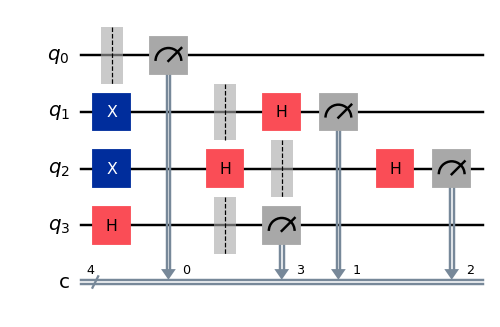

In [ ]:
def bb84(n_raw=2048, eve=False, seed=0, batch=16):
    rng = np.random.default_rng(seed)
    a_bits, a_bas, b_bas = rng.integers(0, 2, n_raw), rng.integers(0, 2, n_raw), rng.integers(0, 2, n_raw)
    e_bas = rng.integers(0, 2, n_raw)
    def transmit(bits, prep_bas, meas_bas, sd):
        out = np.empty(n_raw, int); circs = []
        for s in range(0, n_raw, batch):
            q = QuantumCircuit(batch, batch)
            for i in range(batch):
                if bits[s+i]: q.x(i)
                if prep_bas[s+i]: q.h(i)                # encode
                if meas_bas[s+i]: q.h(i)                # measure in chosen basis
                q.measure(i, i)
            circs.append(q)
        res = SIM.run(transpile(circs, SIM), shots=1, seed_simulator=sd).result()
        for k, q in enumerate(circs):
            m = list(res.get_counts(k))[0][::-1]
            out[k*batch:(k+1)*batch] = [int(ch) for ch in m]
        return out
    if eve:
        e_bits = transmit(a_bits, a_bas, e_bas, seed+1)           # Eve intercepts...
        b_bits = transmit(e_bits, e_bas, b_bas, seed+2)           # ...and resends in her basis
    else:
        b_bits = transmit(a_bits, a_bas, b_bas, seed+1)
    keep = a_bas == b_bas
    ka, kb = a_bits[keep], b_bits[keep]
    sample = rng.permutation(ka.size)[: ka.size // 4]             # public QBER estimation sample
    qber = float((ka[sample] != kb[sample]).mean())
    rest = np.setdiff1d(np.arange(ka.size), sample)
    key = hashlib.sha256(np.packbits(kb[rest]).tobytes()).digest() if qber <= 0.11 else None
    return dict(raw=n_raw, sifted=int(keep.sum()), qber=qber, aborted=key is None, key=key)

r1 = bb84(eve=False, seed=11); r2 = bb84(eve=True, seed=11)
print(pd.DataFrame([{k: v for k, v in r1.items() if k != "key"} | {"scenario": "no eavesdropper"},
                    {k: v for k, v in r2.items() if k != "key"} | {"scenario": "intercept-resend Eve"}]).set_index("scenario"))
K_QKD = r1["key"]; print("\nK_QKD (256 bits) =", K_QKD.hex())

# BB84 circuit diagram (4 example qubits)
ex = QuantumCircuit(4, 4)
for i, (b, ab, bb) in enumerate([(0,0,0),(1,0,1),(1,1,1),(0,1,0)]):
    if b: ex.x(i)
    if ab: ex.h(i)
    ex.barrier(i)
    if bb: ex.h(i)
    ex.measure(i, i)
print("BB84 example: qubit i = Alice bit/basis | Bob basis -> measure")
ex.draw("mpl", scale=.8)

## 3. Chaotic-map validation (key-schedule component)
Bifurcation diagram and largest Lyapunov exponent (tangent-map method using the paper's Jacobian) over a ∈ [−3.14, −2.44] with b=1, c=d=−0.1, x₀=7, y₀=0. Parameters whose trajectory diverges are **rejected by `chaos_digest`**, so the key generator never runs in a divergent region.

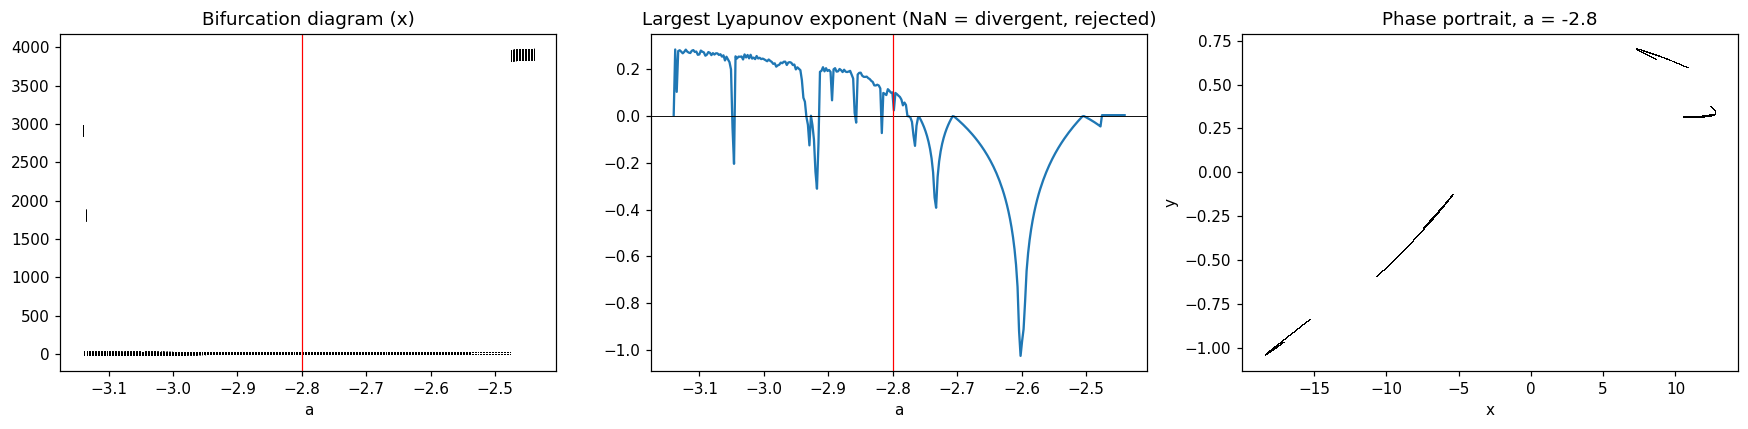

LLE at the working point a=-2.8: +0.0960 (>0, chaotic) | divergent a-values rejected: 0/300


In [ ]:
def lle_and_orbit(a, b=1.0, c=-0.1, d=-0.1, x=7.0, y=0.0, T=1000, K=3000, keep=150):
    v = np.array([1.0, 0.0]); s = 0.0; orb = []
    for k in range(T + K):
        if k >= T:
            J = np.array([[1 + a/(1+y*y), -2*a*x*y/(1+y*y)**2], [c, 1.0]])
            v = J @ v; nv = np.linalg.norm(v); s += math.log(nv); v /= nv
        x, y = rational_map(x, y, a, b, c, d)
        if not (math.isfinite(x) and abs(x) < 1e6 and abs(y) < 1e6): return np.nan, []
        if k >= T + K - keep: orb.append(x)
    return s / K, orb

As = np.linspace(-3.14, -2.44, 300); L = []; fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a_ in As:
    l, orb = lle_and_orbit(a_); L.append(l)
    if orb: ax[0].plot([a_]*len(orb), orb, ",k", alpha=.4)
ax[0].axvline(-2.8, color="r", lw=.8); ax[0].set(title="Bifurcation diagram (x)", xlabel="a")
ax[1].plot(As, L); ax[1].axhline(0, color="k", lw=.6); ax[1].axvline(-2.8, color="r", lw=.8)
ax[1].set(title="Largest Lyapunov exponent (NaN = divergent, rejected)", xlabel="a")
x, y = 7.0, 0.0; xs = []; ys = []
for k in range(21000):
    x, y = rational_map(x, y, -2.8, 1, -0.1, -0.1)
    if k >= 1000: xs.append(x); ys.append(y)
ax[2].plot(xs, ys, ",k"); ax[2].set(title="Phase portrait, a = -2.8", xlabel="x", ylabel="y"); plt.tight_layout(); plt.show()
l28, _ = lle_and_orbit(-2.8, K=100000)
print(f"LLE at the working point a=-2.8: {l28:+.4f} (>0, chaotic) | divergent a-values rejected: {int(np.isnan(L).sum())}/{len(As)}")

## 4. Quantum circuit diagrams
Shown for a 2×2 cover (enlarged to 4×4, so n = 2). Registers: y, x (positions, y₀/x₀ = LSB added by scaling) and c (10 intensity qubits). The structure is identical at 512×512, where n = 10.

(a) NEQR preparation of the 2x2 cover on (y1,x1), then quantum nearest-neighbour scaling (H on y0, x0)


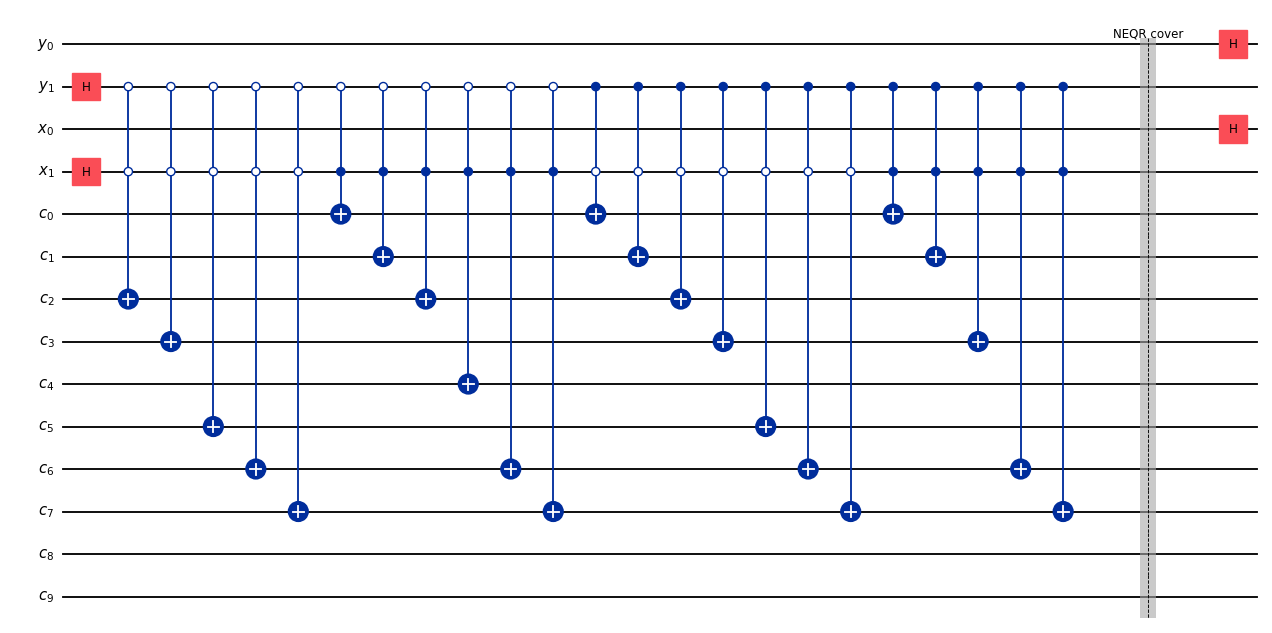

In [ ]:
demo_cover = np.array([[236, 215], [239, 203]])
y, x, c = registers(2)
qa = QuantumCircuit(y, x, c); neqr_prep(qa, y, x, c, demo_cover); qa.barrier(label="NEQR cover"); scale_up(qa, y, x)
print("(a) NEQR preparation of the 2x2 cover on (y1,x1), then quantum nearest-neighbour scaling (H on y0, x0)")
qa.draw("mpl", fold=40, scale=.6)

(b) Embedding: two cyclic rotations of c (|c> -> |4c>, top qubits are |0>), then position-controlled X gates write D(p)


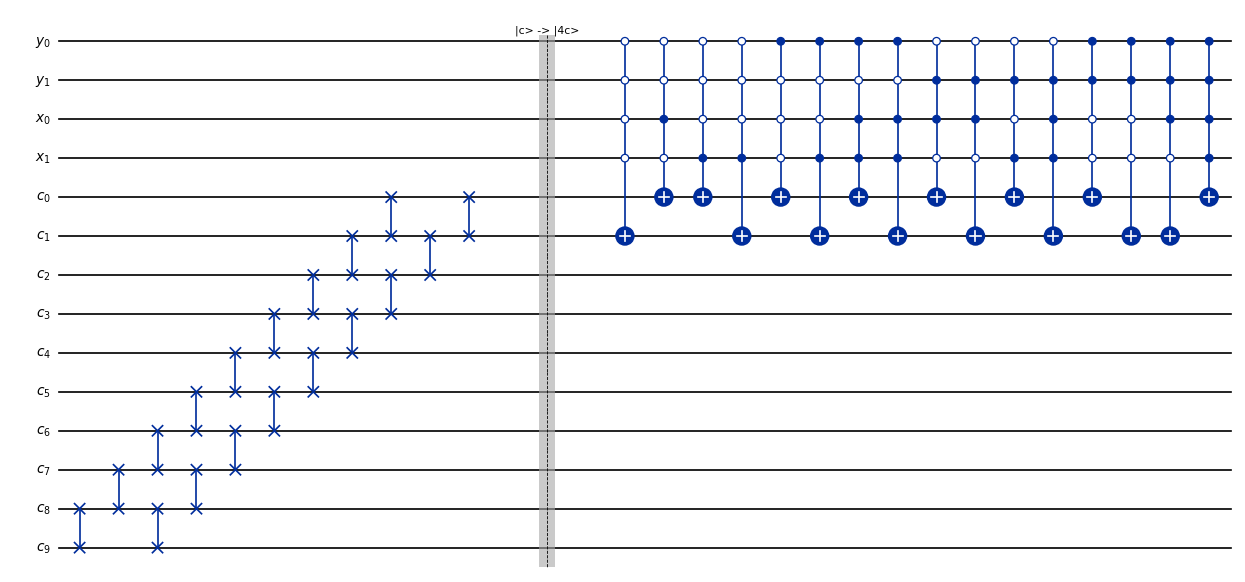

In [ ]:
qb = QuantumCircuit(y, x, c); shift_by_4(qb, c); qb.barrier(label="|c> -> |4c>")
D_demo = np.array([[2,1,3,0],[1,0,2,3],[0,3,1,2],[3,2,0,1]]); write_D(qb, y, x, c, D_demo)
print("(b) Embedding: two cyclic rotations of c (|c> -> |4c>, top qubits are |0>), then position-controlled X gates write D(p)")
qb.draw("mpl", fold=45, scale=.55)

(c) One position-scrambling round: x <- x + 3y + 1, then y <- y + 2x + 3 (mod 4), using Draper QFT adders.
    Each shear is a bijection, so the whole round is a permutation of positions; the inverse uses negated phases.


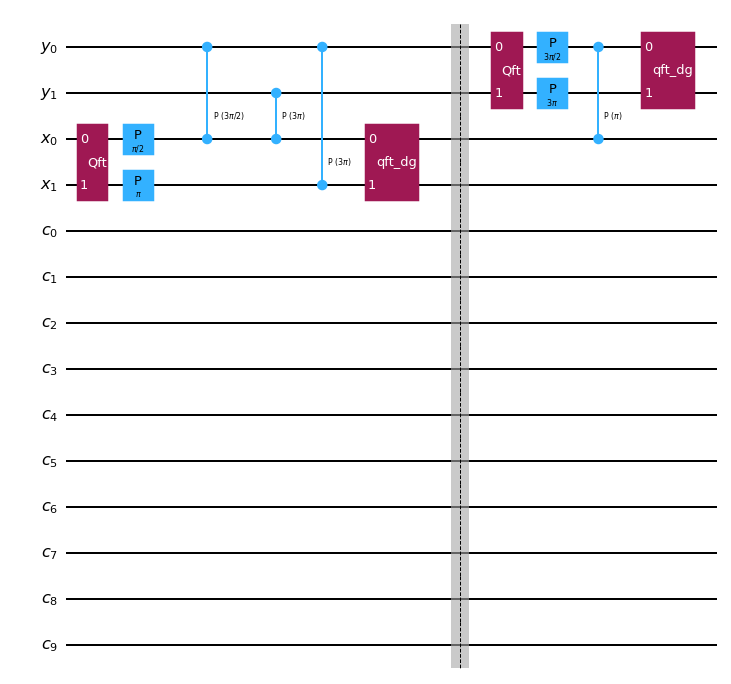

In [ ]:
qcr = QuantumCircuit(y, x, c); draper_affine(qcr, x, y, alpha=3, beta=1); qcr.barrier(); draper_affine(qcr, y, x, alpha=2, beta=3)
print("(c) One position-scrambling round: x <- x + 3y + 1, then y <- y + 2x + 3 (mod 4), using Draper QFT adders.")
print("    Each shear is a bijection, so the whole round is a permutation of positions; the inverse uses negated phases.")
qcr.draw("mpl", fold=40, scale=.65)

(d) Key oracle |p>|c> -> |p>|c XOR k(p)>, shown for two positions: k(0,0)=5, k(3,3)=769


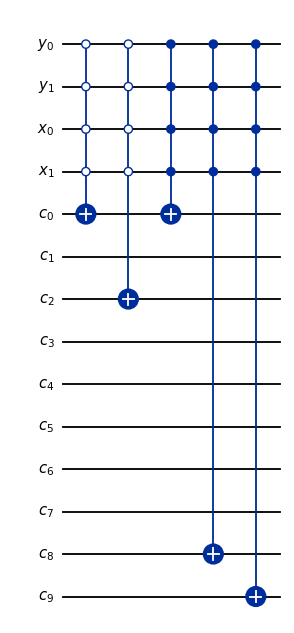

In [ ]:
qd = QuantumCircuit(y, x, c); ks_demo = np.array([[5, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 769]])
key_oracle(qd, y, x, c, ks_demo)
print("(d) Key oracle |p>|c> -> |p>|c XOR k(p)>, shown for two positions: k(0,0)=5, k(3,3)=769")
qd.draw("mpl", fold=40, scale=.6)

(e) End-to-end QC-RDH circuit (sender | channel | receiver). Each shot returns one (p, 4P+D) pair.


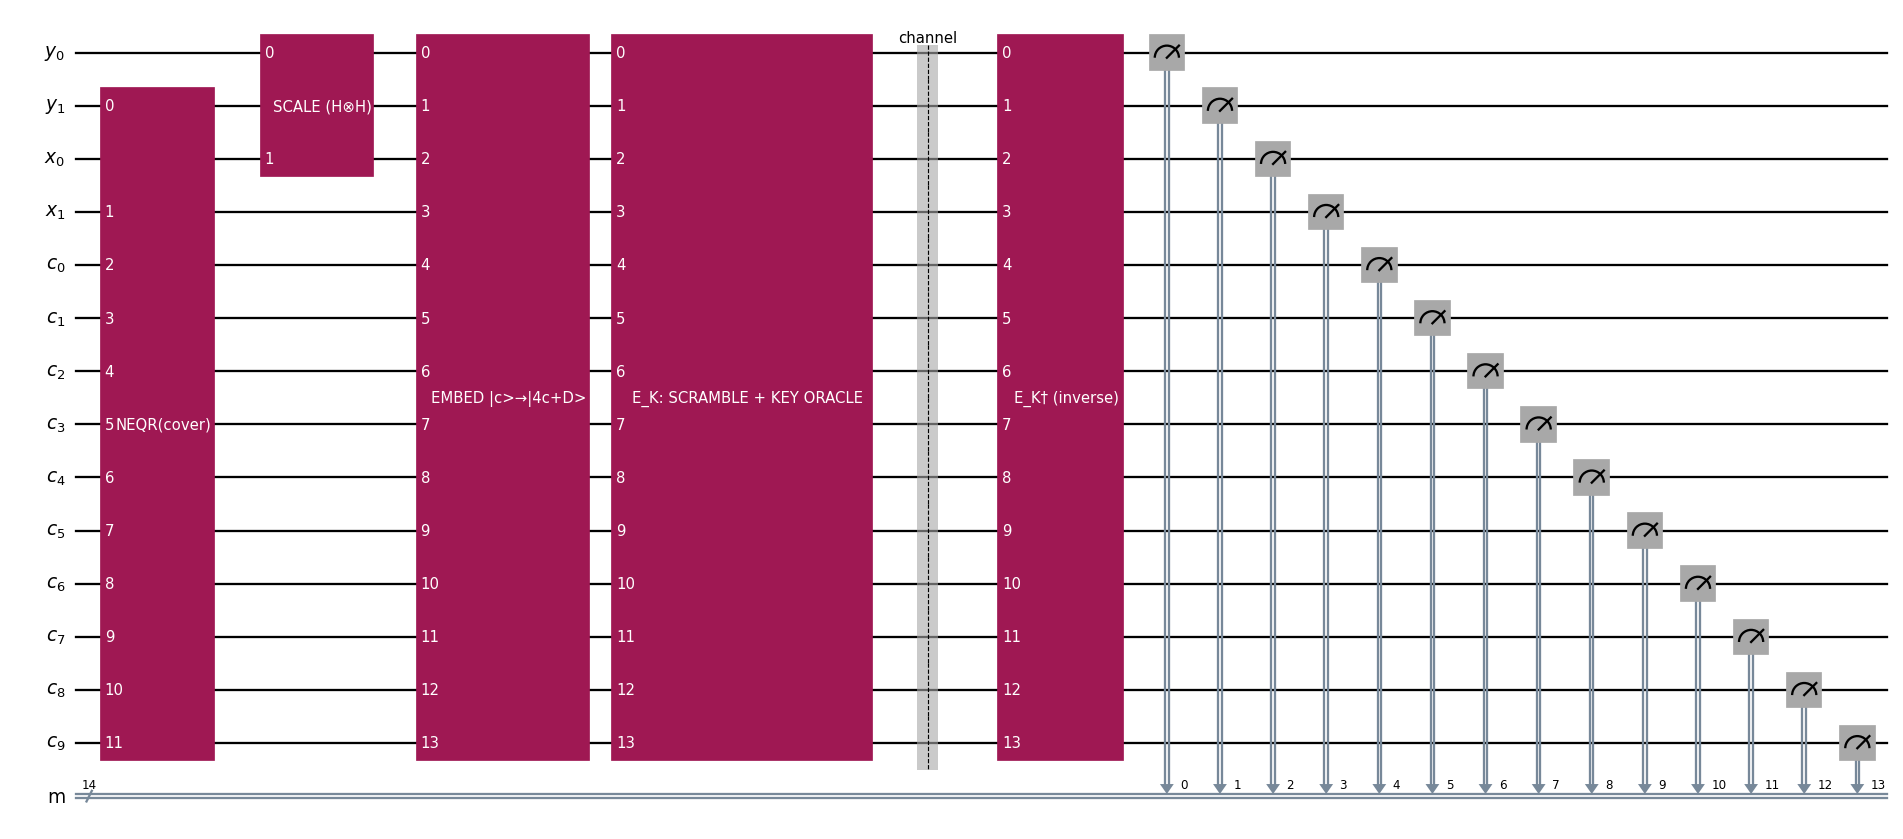

In [ ]:
from qiskit.circuit import Gate
yy, xx, cc = registers(2); cm = ClassicalRegister(14, "m")
full = QuantumCircuit(yy, xx, cc, cm)
full.append(Gate("NEQR(cover)", 12, []), list(yy[1:]) + list(xx[1:]) + list(cc))
full.append(Gate("SCALE (H⊗H)", 2, []), [yy[0], xx[0]])
full.append(Gate("EMBED |c>→|4c+D>", 14, []), list(yy) + list(xx) + list(cc))
full.append(Gate("E_K: SCRAMBLE + KEY ORACLE", 14, []), list(yy) + list(xx) + list(cc)); full.barrier(label="channel")
full.append(Gate("E_K† (inverse)", 14, []), list(yy) + list(xx) + list(cc))
full.measure(list(yy) + list(xx) + list(cc), cm)
print("(e) End-to-end QC-RDH circuit (sender | channel | receiver). Each shot returns one (p, 4P+D) pair.")
full.draw("mpl", fold=-1, scale=.75)

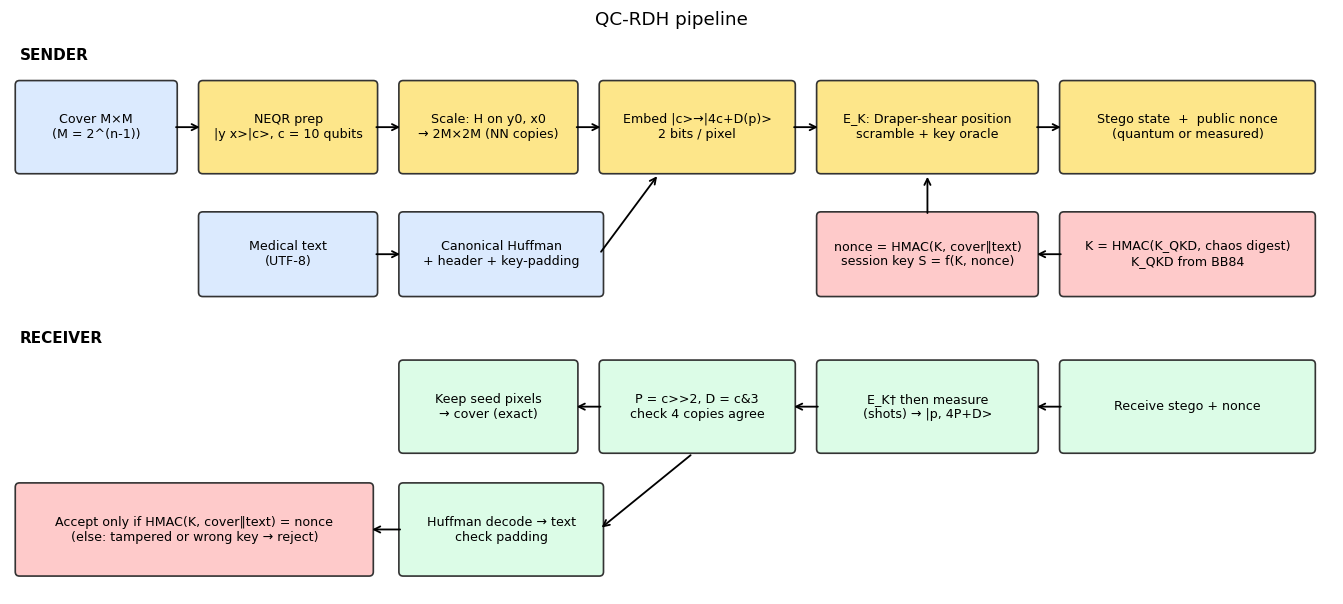

In [ ]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(15.5, 6.6)); ax.axis("off"); ax.set_xlim(0, 15.5); ax.set_ylim(0, 6.6)
def box(x, y, w, h, t, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=fc, ec="#333", lw=1.1))
    ax.text(x + w/2, y + h/2, t, ha="center", va="center", fontsize=8.3)
def arr(x1, y1, x2, y2, s="->"): ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle=s, lw=1.2))
S, Q, R, K = "#dbeafe", "#fde68a", "#dcfce7", "#fecaca"
ax.text(.1, 6.3, "SENDER", fontweight="bold"); ax.text(.1, 2.95, "RECEIVER", fontweight="bold")
box(.1, 5.0, 1.8, 1.0, "Cover M×M\n(M = 2^(n-1))", S); arr(1.9, 5.5, 2.25, 5.5)
box(2.25, 5.0, 2.0, 1.0, "NEQR prep\n|y x>|c>, c = 10 qubits", Q); arr(4.25, 5.5, 4.6, 5.5)
box(4.6, 5.0, 2.0, 1.0, "Scale: H on y0, x0\n→ 2M×2M (NN copies)", Q); arr(6.6, 5.5, 6.95, 5.5)
box(6.95, 5.0, 2.2, 1.0, "Embed |c>→|4c+D(p)>\n2 bits / pixel", Q); arr(9.15, 5.5, 9.5, 5.5)
box(9.5, 5.0, 2.5, 1.0, "E_K: Draper-shear position\nscramble + key oracle", Q); arr(12.0, 5.5, 12.35, 5.5)
box(12.35, 5.0, 2.9, 1.0, "Stego state  +  public nonce\n(quantum or measured)", Q)
box(2.25, 3.55, 2.0, .9, "Medical text\n(UTF-8)", S); arr(4.25, 4.0, 4.6, 4.0)
box(4.6, 3.55, 2.3, .9, "Canonical Huffman\n+ header + key-padding", S); arr(6.9, 4.0, 7.6, 4.95)
box(9.5, 3.55, 2.5, .9, "nonce = HMAC(K, cover‖text)\nsession key S = f(K, nonce)", K); arr(10.75, 4.45, 10.75, 4.95)
box(12.35, 3.55, 2.9, .9, "K = HMAC(K_QKD, chaos digest)\nK_QKD from BB84", K); arr(12.35, 4.0, 12.0, 4.0)
box(12.35, 1.7, 2.9, 1.0, "Receive stego + nonce", R); arr(12.35, 2.2, 12.0, 2.2)
box(9.5, 1.7, 2.5, 1.0, "E_K† then measure\n(shots) → |p, 4P+D>", R); arr(9.5, 2.2, 9.15, 2.2)
box(6.95, 1.7, 2.2, 1.0, "P = c>>2, D = c&3\ncheck 4 copies agree", R); arr(6.95, 2.2, 6.6, 2.2)
box(4.6, 1.7, 2.0, 1.0, "Keep seed pixels\n→ cover (exact)", R)
box(4.6, .25, 2.3, 1.0, "Huffman decode → text\ncheck padding", R); arr(8.0, 1.65, 6.9, .75)
box(.1, .25, 4.1, 1.0, "Accept only if HMAC(K, cover‖text) = nonce\n(else: tampered or wrong key → reject)", K); arr(4.6, .75, 4.2, .75)
ax.set_title("QC-RDH pipeline", fontsize=12); plt.show()

## 5. Gate-level verification
**(i)** The Draper affine adder is exact for every input (n = 3: 8 α × 8 β × 64 inputs).
**(ii)** The *complete* sender circuit (NEQR, scaling, embedding, scrambling, key oracle) is built from real gates for an 8×8 cover with an actual medical text and the QKD key. It has 18 qubits and about 2,000 gates. It is simulated on a statevector and compared **bit-for-bit** with the classical twin `core.embed`.
**(iii)** The receiver applies E† and *measures* (finite shots); the cover and text are recovered from the measurement record alone.

In [ ]:
ok = True
for al in range(8):
    for be in range(8):
        for tv in range(8):
            for sv_ in range(8):
                t_, s_ = QuantumRegister(3, "t"), QuantumRegister(3, "s"); q = QuantumCircuit(t_, s_)
                for i in range(3):
                    if tv >> i & 1: q.x(t_[i])
                    if sv_ >> i & 1: q.x(s_[i])
                draper_affine(q, t_, s_, al, be)
                idx = int(np.argmax(np.abs(Statevector(q).data)))
                ok &= (idx & 7) == (tv + al * sv_ + be) % 8 and (idx >> 3) == sv_
print("(i) Draper adder |t>|s> -> |t + a*s + b>|s> exact for all 4096 cases:", ok)

(i) Draper adder |t>|s> -> |t + a*s + b>|s> exact for all 4096 cases: True


In [ ]:
rng = np.random.default_rng(3)
small = transform.resize(data.camera(), (8, 8), preserve_range=True, anti_aliasing=True).round().astype(np.int64)
msg = "HbA1c 8.1%"
emb_c, enc_c, nonce_q = sender_circuits(small, msg, K_QKD, DEFAULT_CHAOS)
print(f"qubits = {emb_c.num_qubits} | gates: prep+embed = {emb_c.size()}, encryption = {enc_c.size()} ")
ops = emb_c.compose(enc_c).count_ops(); grp = {}
for k_, v_ in ops.items(): grp["mcx (position-controlled)" if k_.startswith("mcx") else k_] = grp.get("mcx (position-controlled)" if k_.startswith("mcx") else k_, 0) + v_
print("gate counts:", grp)
t0 = time.time(); sv_stego = run_statevector(emb_c.compose(enc_c)); print(f"statevector simulation: {time.time()-t0:.1f}s")
q_img, n_branch, amp_sd = statevector_to_image(sv_stego, 4)
c_img, nonce_c = embed(small, msg, K_QKD)
print(f"(ii) branches = {n_branch} (expected 256), amplitude spread = {amp_sd:.1e} (uniform NEQR)")
print(f"     nonce identical: {nonce_q == nonce_c} | QUANTUM CIRCUIT OUTPUT == CLASSICAL TWIN: {np.array_equal(q_img, c_img)}")
assert np.array_equal(q_img, c_img)

qubits = 18 | gates: prep+embed = 504, encryption = 1343 
gate counts: {'cp': 50, 'p': 28, 'swap': 18, 'mcx (position-controlled)': 1727, 'h': 8, 'qft': 8, 'qft_dg': 8, 'barrier': 4}
statevector simulation: 10.8s
(ii) branches = 256 (expected 256), amplitude spread = 3.8e-17 (uniform NEQR)
     nonce identical: True | QUANTUM CIRCUIT OUTPUT == CLASSICAL TWIN: True


In [ ]:
recv = emb_c.compose(enc_c).compose(enc_c.inverse()); recv.measure_all()
shots = 4000
counts = SIM.run(transpile(recv, SIM, optimization_level=0), shots=shots, seed_simulator=7).result().get_counts()
side = 16; meas = -np.ones((side, side), np.int64)
for k in counts:
    i = int(k.replace(" ", ""), 2); meas[i & 15, (i >> 4) & 15] = i >> 8
seen = int((meas >= 0).sum())
P_, D_ = meas >> 2, meas & 3
print(f"(iii) {shots} shots -> {len(counts)} distinct outcomes, positions observed {seen}/256")
print("      cover recovered from measurements:", np.array_equal(P_[0::2, 0::2], small),
      "| 4 redundant copies agree:", bool((P_ == np.repeat(np.repeat(P_[0::2,0::2], 2, 0), 2, 1)).all()))
cov_r, txt_r, rep = extract(c_img, nonce_c, K_QKD); print("      text:", repr(txt_r), rep)
exp_shots = 256 * sum(1/k for k in range(1, 257)); print(f"      expected shots to see all 256 positions (coupon collector): {exp_shots:.0f}")

(iii) 4000 shots -> 256 distinct outcomes, positions observed 256/256
      cover recovered from measurements: True | 4 redundant copies agree: True
      text: 'HbA1c 8.1%' {'consistent': True, 'authentic': True}
      expected shots to see all 256 positions (coupon collector): 1568


## 6. Main theoretical result: the Unitary Diffusion Bound

**Setting.** An NEQR-family image I with N positions is the state |I⟩ = N^(-1/2) Σ_p |p⟩|I_p⟩. For two images,
⟨I|J⟩ = a(I,J)/N, where a(I,J) = N − d_H(I,J) is the number of positions where they agree.
A *fixed-key quantum image cipher* is a unitary U_K, chosen independently of the plaintext, with
U_K(|I⟩⊗|0…0⟩) = |E_K(I)⟩⊗|g_K(I)⟩ for **every** image I. The output E_K(I) has N′ positions, g_K(I) is any ancilla garbage, and decryption is a unitary of the same form.

**Theorem 1 (invariance of the changed-pixel fraction).** For all images I, J: d_H(E_K(I), E_K(J)) / N′ = d_H(I, J) / N.

*Proof.* Unitarity preserves inner products: a(I,J)/N = [a(E(I),E(J))/N′]·⟨g(I)|g(J)⟩. Because |⟨g|g′⟩| ≤ 1, it follows that a(E(I),E(J))/N′ ≥ a(I,J)/N. Applying the same argument to the decryption unitary gives the reverse inequality. ∎

* **Corollary 1 (NPCR ceiling).** A one-pixel plaintext change alters exactly N′/N cipher pixels: NPCR = 100/N %.
* **Corollary 2 (structure).** If N′ = N and the alphabets are equal, E_K is an automorphism of the Hamming graph H(N, q), hence of the form E_K(I)_{π(p)} = σ_p(I_p): a pixel permutation followed by position-wise substitution (automorphism group S_q ≀ S_N; Brouwer, Cohen & Neumaier, *Distance-Regular Graphs*, 1989). Such ciphers are breakable by chosen plaintexts.
* **Proposition 3 (necessity).** A quantum image cipher can exceed the NPCR ceiling only if the unitary it applies depends on the plaintext through classical side information, or if it contains a non-unitary step. QC-RDH uses the synthetic nonce for exactly this purpose.

**Relation to prior work.** Pawela (arXiv:2508.16382v4, Sec. III-E) observes that a unitary preserves the overlap of two NEQR states differing in one pixel, and concludes qualitatively that NPCR-type avalanche cannot come from a coherent unitary layer. Theorem 1 makes this exact and general: it fixes the *number* of changed pixels for arbitrary fixed-key ciphers with ancillas and resizing, and Corollaries 1–2 turn it into a numerical ceiling and a structural reduction that yields the attacks below.

**Scope.** The result covers basis-encoded representations (NEQR, GNEQR, INEQR, NCQI, GQIR) and any gates. It does not cover amplitude encodings (FRQI) or schemes whose output is not a valid image state.

In [ ]:
# (a) Gate-level check of Theorem 1 on random fixed-key ciphers that use every gate family in the
#     literature: affine (Draper) scrambling, key-image XOR, ancilla-based nonlinear S-box,
#     intra-pixel CNOT "diffusion", position-controlled SWAP.
n, q = 3, 8; rng = np.random.default_rng(0); rows_t = []
for trial in range(30):
    E, (y_, x_, c_, a_) = random_fixed_key_cipher(n, q, seed=trial)
    I = rng.integers(0, 256, (8, 8)); d = int(rng.integers(1, 9)); J = I.copy()
    for p in rng.choice(64, d, replace=False): J.flat[p] = (J.flat[p] + int(rng.integers(1, 256))) % 256
    outs = []
    for img in (I, J):
        qc_ = QuantumCircuit(y_, x_, c_, a_); neqr_prep_full(qc_, y_, x_, c_, img); qc_.compose(E, inplace=True)
        o, clean = output_image(run_statevector(qc_), n, q); assert clean and o is not None; outs.append(o)
    rows_t.append(dict(trial=trial, gates=E.size(), changed_in=d, changed_out=int((outs[0] != outs[1]).sum())))
tt = pd.DataFrame(rows_t); display(tt.head(10))
print(f"Theorem 1 holds in {int((tt.changed_in == tt.changed_out).sum())}/{len(tt)} random ciphers "
      f"(changed_out == changed_in every time; NPCR for 1 changed pixel = {100/64:.2f}% = 100/N)")

# (b) The only way to 'diffuse' is to let pixel VALUES control POSITIONS, and that destroys the image state:
E, (y_, x_, c_, a_) = random_fixed_key_cipher(n, q, seed=0)
qc_ = QuantumCircuit(y_, x_, c_, a_); neqr_prep_full(qc_, y_, x_, c_, I); qc_.cx(c_[0], x_[0])
o, _ = output_image(run_statevector(qc_), n, q)
print("value-controlled position gate (CNOT c0 -> x0) still yields a valid NEQR image:", o is not None)

,trial,gates,changed_in,changed_out
0,0,64,8,8
1,1,70,8,8
2,2,75,6,6
3,3,66,4,4
4,4,75,5,5
5,5,78,4,4
6,6,57,7,7
7,7,70,8,8
8,8,67,8,8
9,9,73,3,3


Theorem 1 holds in 30/30 random ciphers (changed_out == changed_in every time; NPCR for 1 changed pixel = 1.56% = 100/N)
value-controlled position gate (CNOT c0 -> x0) still yields a valid NEQR image: False


fixed key: stego pixels changed by a 1-pixel cover change = 4 (Theorem 1 predicts 4)
QC-RDH (SIV): stego pixels changed = 1047564 of 1048576
chosen covers used: 4 | fixed key: victim image recovered exactly = True | QC-RDH (SIV): correct pixels = 0.38% (chance = 0.39%)


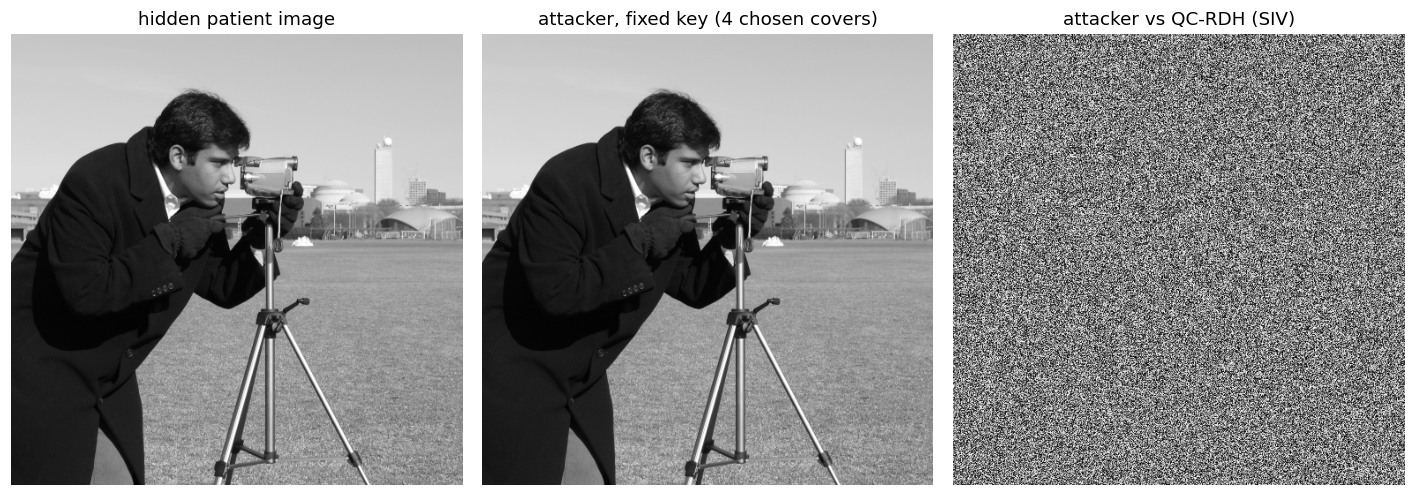

In [ ]:
# (c) Consequence: the fixed-key variant of QC-RDH (no synthetic nonce, i.e. the design of fixed-key quantum
#     RDH / encryption schemes) - a 1-pixel cover change alters exactly N'/N = 4 stego pixels (Theorem 1)...
from skimage import data as _d, transform as _t
victim = np.clip(np.rint(_t.resize(_d.camera(), (512, 512), preserve_range=True, anti_aliasing=True)), 0, 255).astype(np.int64)
c1 = victim.copy(); c1[100, 100] ^= 1
fk = lambda cvr, txt="fixed": fixed_key_embed(cvr, txt, K_QKD)
print("fixed key: stego pixels changed by a 1-pixel cover change =", int((fk(victim) != fk(c1)).sum()), "(Theorem 1 predicts 4)")
siv0, siv1 = embed(victim, "fixed", K_QKD)[0], embed(c1, "fixed", K_QKD)[0]
print("QC-RDH (SIV): stego pixels changed =", int((siv0 != siv1).sum()), f"of {siv0.size}")

# ...and a chosen-cover attack recovers ANY hidden patient image with 4 queries
secret_text = "Patient: R. Sharma, 61F | Dx: stage II breast carcinoma | Rx: letrozole 2.5 mg od"
oracle_fixed = lambda cvr: fixed_key_embed(cvr, "attacker text", K_QKD)
dec_fixed, nq = chosen_cover_attack(oracle_fixed, 512)
rec_fixed = dec_fixed(fixed_key_embed(victim, secret_text, K_QKD))
oracle_siv = lambda cvr: embed(cvr, "attacker text", K_QKD)[0]
dec_siv, _ = chosen_cover_attack(oracle_siv, 512)
rec_siv = dec_siv(embed(victim, secret_text, K_QKD)[0])
print(f"chosen covers used: {nq} | fixed key: victim image recovered exactly = {np.array_equal(rec_fixed, victim)} | "
      f"QC-RDH (SIV): correct pixels = {100*(rec_siv == victim).mean():.2f}% (chance = {100/256:.2f}%)")
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
for a_, im_, t_ in zip(ax, [victim, rec_fixed, rec_siv], ["hidden patient image", f"attacker, fixed key ({nq} chosen covers)", "attacker vs QC-RDH (SIV)"]):
    a_.imshow(im_, cmap="gray", vmin=0, vmax=255); a_.set_title(t_); a_.axis("off")
plt.tight_layout(); plt.show()

### 6d. Applying the bound to the closest prior scheme (NEQRX, *IEEE TDSC* 2026)
NEQRX encrypts with a generalised affine transform X′ = sX+P, Y′ = tY+Q (mod 2ⁿ) and an XOR with a logistic-map key image, then a data hider CNOTs scrambled data bits into the LSBs. All keys are fixed and independent of the image, so by Corollary 2 the cipher is a pixel permutation plus a per-position XOR. Below it is re-implemented as described (key L0 = 0.5557924316949603 from the paper; s, t, P, Q chosen to satisfy its conditions), then (i) its *plaintext* NPCR is measured, which the paper does not report (its Table VI varies the key), and (ii) it is broken with 4 chosen plaintexts. Every operation is a basis-state permutation, so this exact classical twin gives the same result as the circuit.

NEQRX-style cipher, 1-pixel plaintext change: 1 cipher pixel(s) changed, NPCR = 0.00038% (Theorem 1 ceiling 100/N = 0.00038%)
chosen plaintexts used: 4 | 7 MSB planes of victim recovered exactly: True | PSNR of recovered image = 77.89 dB (only the data-carrying LSBs differ)


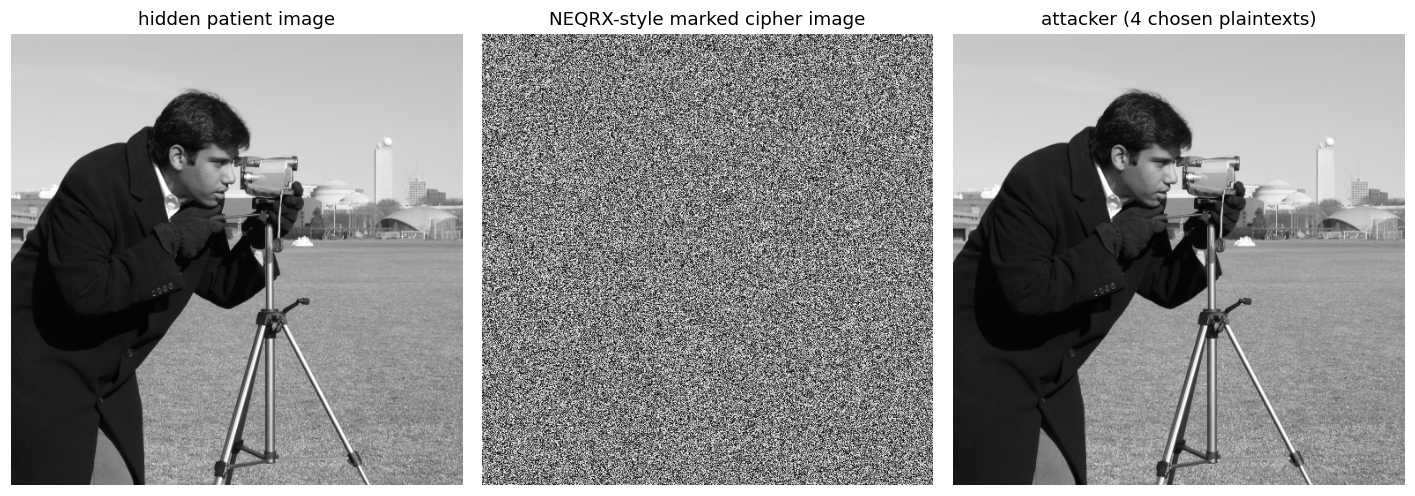

In [ ]:
def logistic_key(M, L0=0.5557924316949603, mu=3.99):
    x = L0; ks = np.empty(M*M, np.int64)
    for k in range(M*M):
        x = mu * x * (1 - x); ks[k] = int(x * 1e14) % 256
    return ks.reshape(M, M)
KS_NX = logistic_key(512)
def neqrx_encrypt(I, s=5, t=3, P=77, Q=141):
    M = I.shape[0]; Y, X = np.indices((M, M)); E = np.empty_like(I)
    E[(t*Y + Q) % M, (s*X + P) % M] = I                      # GAT position scrambling
    return E ^ KS_NX                                          # logistic-map key image, quantum XOR
def neqrx_embed(E, bits, a=7, b=19):
    M = E.shape[0]; Mx = np.zeros(M*M, np.int64); Mx[:len(bits)] = bits; Mx = Mx.reshape(M, M)
    Y, X = np.indices((M, M)); Ms = np.empty_like(Mx); Ms[(a*Y + b) % M, (a*X + b) % M] = Mx
    return E ^ Ms                                             # CNOT: scrambled data bit -> LSB

# (i) plaintext sensitivity: one pixel of the plaintext changed
p1 = victim.copy(); p1[100, 100] ^= 1
d_ = int((neqrx_encrypt(victim) != neqrx_encrypt(p1)).sum())
print(f"NEQRX-style cipher, 1-pixel plaintext change: {d_} cipher pixel(s) changed, NPCR = {100*d_/victim.size:.5f}% "
      f"(Theorem 1 ceiling 100/N = {100/victim.size:.5f}%)")

# (ii) chosen-plaintext attack: zero image + 3 index-byte images (18 position bits)
def perm_xor_attack(enc, M):
    Z = enc(np.zeros((M, M), np.int64)); idx = np.arange(M*M).reshape(M, M); owner = np.zeros_like(Z)
    nq = math.ceil(math.log2(M*M) / 8)
    for j in range(nq): owner |= (enc((idx >> (8*j)) & 255) ^ Z) << (8*j)
    def dec(C):
        rec = np.zeros(M*M, np.int64); rec[owner.ravel()] = (C ^ Z).ravel(); return rec.reshape(M, M)
    return dec, 1 + nq
dec_nx, nq_nx = perm_xor_attack(neqrx_encrypt, 512)
hidden_bits = np.unpackbits(np.frombuffer(secret_text.encode(), np.uint8)).astype(np.int64)
marked = neqrx_embed(neqrx_encrypt(victim), hidden_bits)       # what is transmitted / stored
rec_nx = dec_nx(marked)
mse = ((rec_nx - victim)**2).mean(); psnr_nx = float("inf") if mse == 0 else 10*np.log10(255**2/mse)
print(f"chosen plaintexts used: {nq_nx} | 7 MSB planes of victim recovered exactly: {np.array_equal(rec_nx >> 1, victim >> 1)} | "
      f"PSNR of recovered image = {psnr_nx:.2f} dB (only the data-carrying LSBs differ)")
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
for a_, im_, t_ in zip(ax, [victim, marked, rec_nx], ["hidden patient image", "NEQRX-style marked cipher image", f"attacker ({nq_nx} chosen plaintexts)"]):
    a_.imshow(im_, cmap="gray", vmin=0, vmax=255); a_.set_title(t_); a_.axis("off")
plt.tight_layout(); plt.show()

## 7. Experiments on 512×512 images (maximum-capacity payload)
The built-in scikit-image test images are used so the notebook runs offline. To use USC-SIPI / BOSSBase / BOWS-2 / UCID, replace `load_gray`.

gross capacity 2,097,152 bits | payload 335,000 chars -> 2,091,973 bits incl. header (99.75% full)


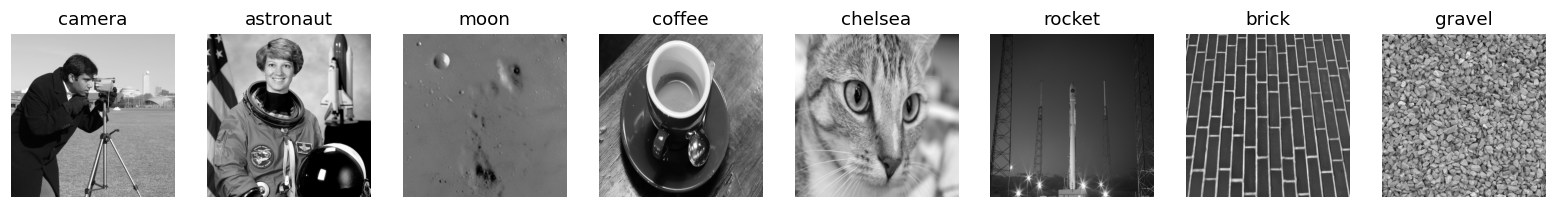

In [ ]:
def load_gray(name):
    im = getattr(data, name)()
    if im.ndim == 3: im = color.rgb2gray(im[..., :3]) * 255
    return np.clip(np.rint(transform.resize(im, (512, 512), preserve_range=True, anti_aliasing=True)), 0, 255).astype(np.int64)
names = ["camera", "astronaut", "moon", "coffee", "chelsea", "rocket", "brick", "gravel"]
IM = {n: load_gray(n) for n in names}
cap = capacity(512, 512)
alph = np.frombuffer(b"ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789 .,;:-/()%+", np.uint8)
rng = np.random.default_rng(7); n_chars = 340000
while True:
    max_text = bytes(rng.choice(alph, n_chars)).decode()
    used = len(encode_payload(max_text.encode()))
    if used <= cap: break
    n_chars -= 1000
print(f"gross capacity {cap:,} bits | payload {n_chars:,} chars -> {used:,} bits incl. header ({100*used/cap:.2f}% full)")
fig, ax = plt.subplots(1, 8, figsize=(18, 2.6))
for a_, n in zip(ax, names): a_.imshow(IM[n], cmap="gray"); a_.set_title(n); a_.axis("off")
plt.show()

In [ ]:
rows, STEGO = [], {}
bad_chaos = dict(DEFAULT_CHAOS); bad_chaos["x0"] += 1e-12
bad_qkd = bytes([K_QKD[0] ^ 1]) + K_QKD[1:]
alt_text = max_text[:5000] + ("A" if max_text[5000] != "A" else "B") + max_text[5001:]
for n in names:
    cv = IM[n]
    t0 = time.time(); Cst, nc = embed(cv, max_text, K_QKD); t1 = time.time()
    rc, rt, rep = extract(Cst, nc, K_QKD); t2 = time.time(); STEGO[n] = (Cst, rc)
    mse = float(np.mean((cv - rc) ** 2))
    c1 = cv.copy(); c1[256, 256] ^= 1
    nk1 = npcr_uaci(Cst, embed(cv, max_text, K_QKD, bad_chaos)[0]); nk2 = npcr_uaci(Cst, embed(cv, max_text, bad_qkd)[0])
    np1 = npcr_uaci(Cst, embed(c1, max_text, K_QKD)[0]); nt1 = npcr_uaci(Cst, embed(cv, alt_text, K_QKD)[0])
    wk = extract(Cst, nc, K_QKD, bad_chaos)[2]["authentic"] or extract(Cst, nc, bad_qkd)[2]["authentic"]
    trng = np.random.default_rng(1); det = 0; NT = 10
    for _ in range(NT):
        T = Cst.copy(); yy_, xx_ = trng.integers(0, 1024, 2); T[yy_, xx_] ^= int(trng.integers(1, 1024))
        det += not extract(T, nc, K_QKD)[2]["authentic"]
    rows.append(dict(Image=n, EC_bits=cap, payload_bits=used, bpp_stego=cap/Cst.size, bpp_cover=cap/cv.size,
        exact_image=bool(np.array_equal(rc, cv)), exact_text=(rt == max_text), authentic=rep["authentic"],
        PSNR=float("inf") if mse == 0 else 10*math.log10(255**2/mse),
        SSIM=ssim(cv.astype(np.uint8), rc.astype(np.uint8), data_range=255),
        H_cover=entropy(cv, 256), H_stego=entropy(Cst, 1024), chi2_stego=chi_square(Cst, 1024),
        r_cover_H=corr(cv, 1, 0), r_H=corr(Cst, 1, 0), r_V=corr(Cst, 0, 1), r_D=corr(Cst, 1, 1),
        NPCR_chaos=nk1[0], UACI_chaos=nk1[1], NPCR_qkd=nk2[0], UACI_qkd=nk2[1],
        NPCR_1px=np1[0], UACI_1px=np1[1], NPCR_1char=nt1[0], UACI_1char=nt1[1],
        wrong_key_accepted=wk, tamper_detected=f"{det}/{NT}", t_embed=t1-t0, t_extract=t2-t1))
    print(f"{n:10s} image exact={rows[-1]['exact_image']} text exact={rows[-1]['exact_text']} authentic={rep['authentic']} tamper {det}/{NT}")
df = pd.DataFrame(rows)
assert df.exact_image.all() and df.exact_text.all() and df.authentic.all() and not df.wrong_key_accepted.any()

camera     image exact=True text exact=True authentic=True tamper 10/10
astronaut  image exact=True text exact=True authentic=True tamper 10/10
moon       image exact=True text exact=True authentic=True tamper 10/10
coffee     image exact=True text exact=True authentic=True tamper 10/10
chelsea    image exact=True text exact=True authentic=True tamper 10/10
rocket     image exact=True text exact=True authentic=True tamper 10/10
brick      image exact=True text exact=True authentic=True tamper 10/10
gravel     image exact=True text exact=True authentic=True tamper 10/10


In [ ]:
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("TABLE A: capacity and reversibility"); display(df[["Image","EC_bits","payload_bits","bpp_stego","bpp_cover","exact_image","exact_text","authentic","PSNR","SSIM","t_embed","t_extract"]].round(3))
print("TABLE B: statistical security (10-bit stego: ideal entropy 10; chi-square critical value at 5% with 1023 dof ≈ 1098)")
display(df[["Image","H_cover","H_stego","chi2_stego","r_cover_H","r_H","r_V","r_D"]].round(4))
print("TABLE C: sensitivity, % (ideal for random 10-bit data: NPCR ≈ 99.90, UACI ≈ 33.37)")
display(df[["Image","NPCR_chaos","UACI_chaos","NPCR_qkd","UACI_qkd","NPCR_1px","UACI_1px","NPCR_1char","UACI_1char","wrong_key_accepted","tamper_detected"]].round(3))
print("Ideal NPCR for 10-bit = 100*(1-1/1024) = %.2f%%, ideal UACI = %.2f%%" % (100*(1-1/1024), 100*(1024+1)/(3*1024)))

TABLE A: capacity and reversibility


,Image,EC_bits,payload_bits,bpp_stego,bpp_cover,exact_image,exact_text,authentic,PSNR,SSIM,t_embed,t_extract
0,camera,2097152,2091973,2.0,8.0,True,True,True,inf,1.0,0.121,0.563
1,astronaut,2097152,2091973,2.0,8.0,True,True,True,inf,1.0,0.116,0.412
2,moon,2097152,2091973,2.0,8.0,True,True,True,inf,1.0,0.109,0.399
3,coffee,2097152,2091973,2.0,8.0,True,True,True,inf,1.0,0.109,0.402
4,chelsea,2097152,2091973,2.0,8.0,True,True,True,inf,1.0,0.121,0.425
5,rocket,2097152,2091973,2.0,8.0,True,True,True,inf,1.0,0.113,0.424
6,brick,2097152,2091973,2.0,8.0,True,True,True,inf,1.0,0.108,0.380
7,gravel,2097152,2091973,2.0,8.0,True,True,True,inf,1.0,0.163,0.728


TABLE B: statistical security (10-bit stego: ideal entropy 10; chi-square critical value at 5% with 1023 dof ≈ 1098)


,Image,H_cover,H_stego,chi2_stego,r_cover_H,r_H,r_V,r_D
0,camera,7.2317,9.9993,1085.2754,0.9781,0.0005,0.0004,0.0005
1,astronaut,7.4545,9.9993,977.2012,0.9789,0.0009,-0.0014,-0.0021
2,moon,4.8850,9.9993,991.4551,0.9532,0.0004,-0.0002,0.0003
3,coffee,7.6422,9.9993,981.2168,0.9773,-0.0001,-0.0006,-0.0003
4,chelsea,6.9884,9.9993,1065.9785,0.9803,-0.0016,0.0004,0.0014
5,rocket,6.6350,9.9993,994.7305,0.9410,-0.0001,-0.0004,-0.0001
6,brick,5.4553,9.9993,1003.5996,0.8925,-0.0006,-0.0007,0.0007
7,gravel,7.2531,9.9993,1030.2852,0.8648,-0.0003,-0.0010,0.0014


TABLE C: sensitivity, % (ideal for random 10-bit data: NPCR ≈ 99.90, UACI ≈ 33.37)


,Image,NPCR_chaos,UACI_chaos,NPCR_qkd,UACI_qkd,NPCR_1px,UACI_1px,NPCR_1char,UACI_1char,wrong_key_accepted,tamper_detected
0,camera,99.899,33.356,99.897,33.400,99.906,33.356,99.900,33.372,False,10/10
1,astronaut,99.900,33.352,99.905,33.407,99.903,33.341,99.903,33.380,False,10/10
2,moon,99.908,33.352,99.899,33.377,99.902,33.375,99.909,33.412,False,10/10
3,coffee,99.900,33.319,99.897,33.357,99.901,33.358,99.900,33.367,False,10/10
4,chelsea,99.899,33.379,99.902,33.374,99.901,33.390,99.900,33.316,False,10/10
5,rocket,99.903,33.336,99.908,33.371,99.905,33.372,99.903,33.353,False,10/10
6,brick,99.903,33.343,99.904,33.359,99.899,33.394,99.903,33.372,False,10/10
7,gravel,99.899,33.354,99.903,33.337,99.901,33.354,99.903,33.336,False,10/10


Ideal NPCR for 10-bit = 100*(1-1/1024) = 99.90%, ideal UACI = 33.37%


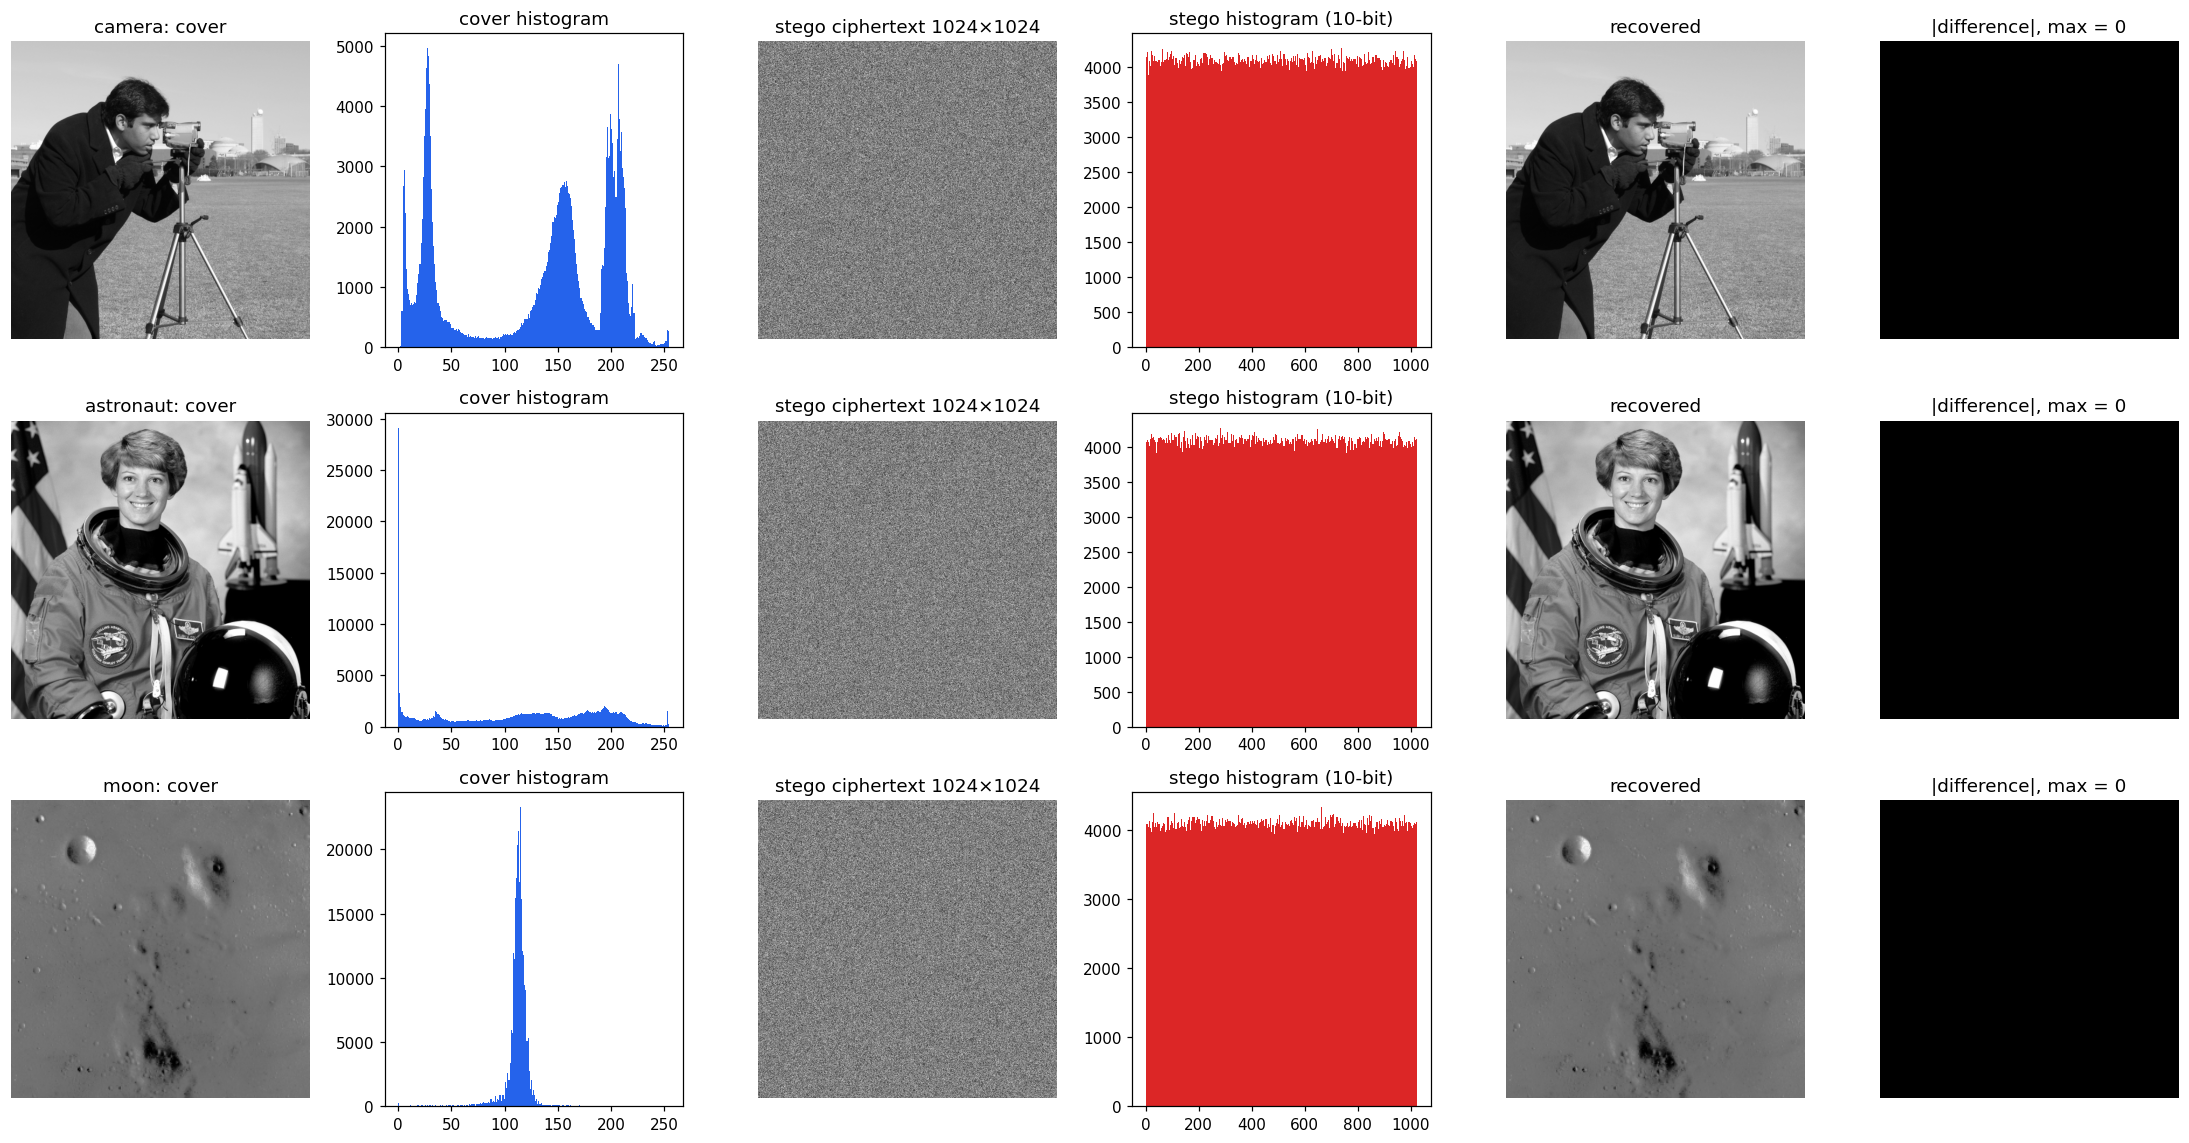

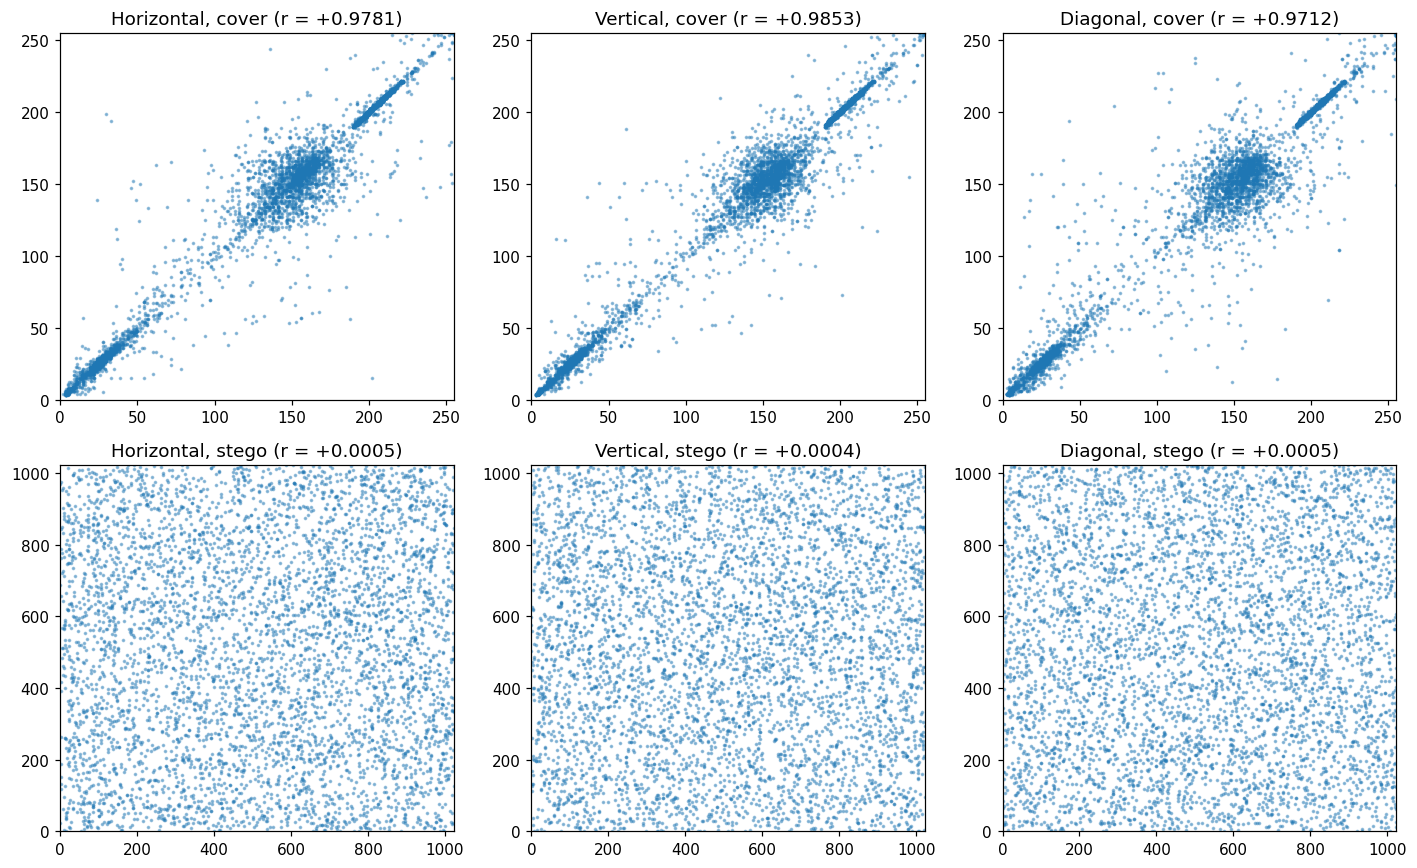

In [ ]:
sel = ["camera", "astronaut", "moon"]
fig, ax = plt.subplots(3, 6, figsize=(20, 10.5))
for r, n in enumerate(sel):
    Cst, rc = STEGO[n]
    ax[r,0].imshow(IM[n], cmap="gray", vmin=0, vmax=255); ax[r,0].set_title(f"{n}: cover")
    ax[r,1].hist(IM[n].ravel(), 256, color="#2563eb"); ax[r,1].set_title("cover histogram")
    ax[r,2].imshow(Cst, cmap="gray", vmin=0, vmax=1023); ax[r,2].set_title("stego ciphertext 1024×1024")
    ax[r,3].hist(Cst.ravel(), 256, color="#dc2626"); ax[r,3].set_title("stego histogram (10-bit)")
    ax[r,4].imshow(rc, cmap="gray", vmin=0, vmax=255); ax[r,4].set_title("recovered")
    ax[r,5].imshow(np.abs(IM[n]-rc), cmap="gray", vmin=0, vmax=255); ax[r,5].set_title(f"|difference|, max = {np.abs(IM[n]-rc).max()}")
    for k in (0, 2, 4, 5): ax[r,k].axis("off")
plt.tight_layout(); plt.show()

Cst, _ = STEGO["camera"]; cv = IM["camera"]; rr = np.random.default_rng(0)
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for j, (dx, dy, nm) in enumerate([(1,0,"Horizontal"), (0,1,"Vertical"), (1,1,"Diagonal")]):
    for i, (im, lab, lim) in enumerate([(cv, "cover", 255), (Cst, "stego", 1023)]):
        ys_ = rr.integers(0, im.shape[0]-dy, 5000); xs_ = rr.integers(0, im.shape[1]-dx, 5000)
        ax[i,j].scatter(im[ys_, xs_], im[ys_+dy, xs_+dx], s=2, alpha=.4)
        ax[i,j].set(title=f"{nm}, {lab} (r = {corr(im, dx, dy):+.4f})", xlim=(0, lim), ylim=(0, lim))
plt.tight_layout(); plt.show()

### Realistic medical record

In [ ]:
record = ("Patient: A. Kumar, 54M | Dx: type-2 diabetes, early nephropathy | Rx: metformin 500 mg bd; ramipril 5 mg od | "
          "HbA1c 8.1% | eGFR 62 mL/min | BP 138/86 | Plan: repeat urine ACR, review in 3 months. ") * 150
raw = len(record.encode()) * 8; enc_bits = len(encode_payload(record.encode()))
Cm, ncm = embed(IM["camera"], record, K_QKD); rcm, rtm, repm = extract(Cm, ncm, K_QKD)
print(f"{len(record):,} chars = {raw:,} bits raw -> {enc_bits:,} bits with Huffman + header ({100*enc_bits/raw:.1f}%), "
      f"{100*enc_bits/cap:.1f}% of capacity | image exact {np.array_equal(rcm, IM['camera'])} | text exact {rtm == record} | {repm}")

29,400 chars = 235,200 bits raw -> 145,454 bits with Huffman + header (61.8%), 6.9% of capacity | image exact True | text exact True | {'consistent': True, 'authentic': True}


## 8. Capacity comparison
The baseline values are the **average embedding rates as reported in the original paper**; they were not re-implemented here. Because enlargement makes the stego image 4× larger with 10-bit pixels, QC-RDH is reported in three normalisations. Reviewers expect the per-stego-pixel figure; per-cover-pixel is the convention used by the original paper's 4.14 bpp.

**NEQRX (closest quantum RDH).** NEQRX reports ER = 8 bpp, computed as a 512×512×8-bit secret over a 512×512 cover, but it states that the secret is spread over **eight** covers and that embedding is a CNOT into the **LSB** of each encrypted pixel. Its mechanism therefore carries **1 bit per cover pixel**, with no image expansion. The table below normalises both schemes per cover pixel and per transmitted bit. QC-RDH carries more per cover pixel because it enlarges the image 4×; per transmitted bit the two are of the same order. **We claim neither a capacity record nor superiority over NEQRX.**

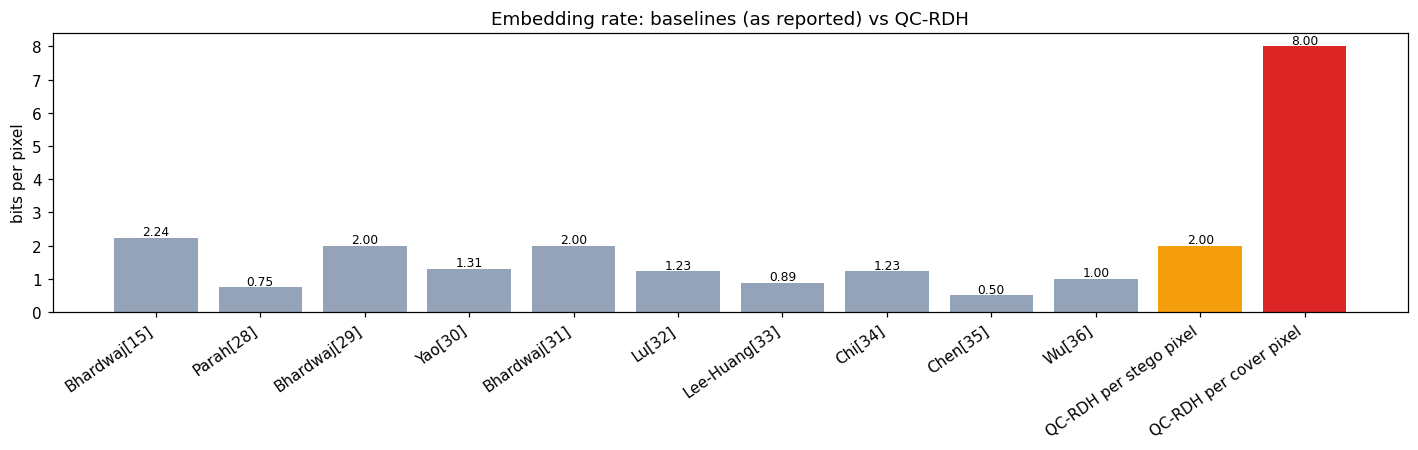

bits per stego pixel                                      2.0
bits per cover pixel                                      8.0
payload bits per transmitted stego bit (10-bit pixels)    0.2
dtype: float64


,QC-RDH,NEQRX (as described)
bits per cover pixel,8.0,1.0
stego pixels / cover pixels,4,1
bits per transmitted bit,0.2,0.125
content authentication,yes (SIV),no
plaintext NPCR (1 pixel),≈99.9 % (SIV),"100/N % (Theorem 1, Sec. 6d)"
separable (third-party data hider),no,yes


In [ ]:
base = {"Bhardwaj[15]":2.24, "Parah[28]":0.75, "Bhardwaj[29]":2.00, "Yao[30]":1.31, "Bhardwaj[31]":2.00,
        "Lu[32]":1.23, "Lee-Huang[33]":0.89, "Chi[34]":1.23, "Chen[35]":0.50, "Wu[36]":1.00}
ours = {"QC-RDH per stego pixel": cap/(1024*1024), "QC-RDH per cover pixel": cap/(512*512)}
lab = list(base) + list(ours); val = list(base.values()) + list(ours.values())
plt.figure(figsize=(13, 4.2)); b = plt.bar(lab, val, color=["#94a3b8"]*len(base) + ["#f59e0b", "#dc2626"])
for bb, v in zip(b, val): plt.text(bb.get_x()+bb.get_width()/2, v+.08, f"{v:.2f}", ha="center", fontsize=8)
plt.ylabel("bits per pixel"); plt.xticks(rotation=35, ha="right"); plt.title("Embedding rate: baselines (as reported) vs QC-RDH"); plt.tight_layout(); plt.show()
print(pd.Series({"bits per stego pixel": cap/(1024*1024), "bits per cover pixel": cap/(512*512),
                 "payload bits per transmitted stego bit (10-bit pixels)": cap/(1024*1024*10)}).round(3))
cmp = pd.DataFrame({
    "bits per cover pixel": [cap/(512*512), 1.0],
    "stego pixels / cover pixels": [4, 1],
    "bits per transmitted bit": [cap/(1024*1024*10), 1/8],
    "content authentication": ["yes (SIV)", "no"],
    "plaintext NPCR (1 pixel)": ["≈99.9 % (SIV)", "100/N % (Theorem 1, Sec. 6d)"],
    "separable (third-party data hider)": ["no", "yes"]}, index=["QC-RDH", "NEQRX (as described)"]).T
display(cmp)

## 9. Quantum resources for a 512×512 cover (computed from the actual data)

In [ ]:
n = 10; Cst, nc = embed(IM["camera"], max_text, K_QKD)
cv = IM["camera"]; S_ = session(master_key(K_QKD), nc); ks = keystream(S_, 1024)
ones_cover = int(np.unpackbits(cv.astype(np.uint8)).sum())
ones_D = int(used * 0.5 + (cap - used) * 0.5)
ones_key = int(np.unpackbits(ks.astype(">u2").view(np.uint8)).sum())
qft = n * (n - 1) // 2 + n
res = pd.DataFrame([
    ("qubits: position / intensity / total", f"{2*n} / {NBITS_C} / {2*n+NBITS_C}"),
    ("NEQR preparation (cover 1-bits), MCX with 18 controls", f"{ones_cover:,}"),
    ("scaling: H gates", "2"),
    ("embedding shift |c>->|4c>: SWAP gates", f"{2*(NBITS_C-1)}"),
    ("embedding write D: MCX with 20 controls (≈ number of 1-bits)", f"≈ {ones_D:,}"),
    ("position scrambling: Draper rounds x (2 QFT + ≤n² CP + n P)", f"{2*ROUNDS} shears ≈ {2*ROUNDS*(2*qft + n*n + n):,} gates, O(R n²)"),
    ("key oracle: MCX with 20 controls (key 1-bits)", f"{ones_key:,}"),
    ("receiver read-out shots (coupon collector, N = 2^20)", f"≈ {2**20 * (math.log(2**20) + 0.5772):,.0f}")], columns=["resource", "count"])
display(res)
print("The data-dependent oracles (preparation, write-D, key) cost O(2^(2n)), the same order as preparing any NEQR image;\n"
      "this is inherent to NEQR-based schemes. Scrambling is O(R n^2), i.e. polylogarithmic in the number of pixels.")

,resource,count
0,qubits: position / intensity / total,20 / 10 / 30
1,"NEQR preparation (cover 1-bits), MCX with 18 c...","989,044"
2,scaling: H gates,2
3,embedding shift |c>->|4c>: SWAP gates,18
4,embedding write D: MCX with 20 controls (≈ num...,"≈ 1,048,576"
5,position scrambling: Draper rounds x (2 QFT + ...,"8 shears ≈ 1,760 gates, O(R n²)"
6,key oracle: MCX with 20 controls (key 1-bits),"5,245,741"
7,"receiver read-out shots (coupon collector, N =...","≈ 15,141,588"


The data-dependent oracles (preparation, write-D, key) cost O(2^(2n)), the same order as preparing any NEQR image;
this is inherent to NEQR-based schemes. Scrambling is O(R n^2), i.e. polylogarithmic in the number of pixels.


## 10. Limitations (state these in the paper)
* **Simulation, not hardware.** Results come from exact statevector simulation (Sec. 5) and the exact classical twin (Sec. 7). The two agree bit-for-bit, and no NISQ hardware run is claimed.
* **Read-out cost.** A fully quantum channel needs about N·ln N copies of the stego state (no-cloning), so the hybrid mode (B) is the practical one.
* **No quantum speed-up is claimed.** The quantum benefits are QKD-based key distribution, NEQR's logarithmic qubit count, and post-quantum security (no factoring or discrete-log component).
* **Deterministic encryption.** The synthetic nonce reveals only whether the same cover and text were sent twice (the standard SIV property).
* **Baselines.** The comparison values are as reported in the literature and were not re-implemented.
* **Not separable.** Embedding is done by the sender who holds the image key; unlike NEQRX, a third-party data hider cannot embed into an already-encrypted image. Theorem 1 applies to any such third-party layer as well, so a separable variant would need its own nonce.
* **Image expansion.** The stego image has 4× the pixels at 10 bits, which is the cost of the reversible nearest-neighbour expansion.
* **NEQRX re-implementation.** Sec. 6d follows the NEQRX description; parameters not given in the paper (s, t, P, Q, μ, data-hider affine) were chosen to satisfy its stated conditions. The attack does not depend on their values.

In [ ]:
df.to_csv("qcrdh_results.csv", index=False)
try:
    from google.colab import files; files.download("qcrdh_results.csv")
except Exception:
    print("saved qcrdh_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>